In [13]:
import numpy as np
import pandas as pd
import re
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.base import clone
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import balanced_accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
import joblib
from pathlib import Path
from collections import Counter
import importlib
import time
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
import sklearn
from sklearn.metrics import precision_score, recall_score
import hashlib
import json, warnings
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.exceptions import InconsistentVersionWarning
import sklearn.compose._column_transformer as _ct
import json, html
from IPython.display import display, HTML
import json, importlib
from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import StratifiedGroupKFold


# В нашем черновике также рассматривается наиболее успешная по метрикам модель G. Чтобы в дальнейшем не было недопониманий, оставляем здессь пояснение. G=Grigoriy. Гриша оказался довольно чутким с точки зрения распознавания чужих эмоций и эмпатичным, а потому заслужил носить это гордое имя

In [14]:
df = pd.read_json('data/hw1_train.jsonl', lines=True)
df['reaction'] = df['labels'].apply(lambda x: x.get('reaction') if isinstance(x, dict) else None)
df_reaction = df[df['reaction'].notna()].copy()
print('Размер датасета:', df_reaction.shape)


Размер датасета: (3000, 6)


In [15]:
def get_dialog_text(turns):
    return '\n'.join((turn['role'] + ': ' + turn['text'] for turn in turns))
df_reaction['dialog_text'] = df_reaction['turns'].apply(get_dialog_text)
X = df_reaction['dialog_text']
y = df_reaction['reaction']
print('Количество текстов:', len(X))
print('Количество меток:', len(y))
print('\nМетка реакции:', y.iloc[0])


Количество текстов: 3000
Количество меток: 3000

Пример текста:
user: it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in this concept and into which it may result?
In the context of the equation “1+1=2+1+1=?,” if we want to explore the possibility of using a modulus to determine the result, we can consider different modulus values and see how they affect the equation.

Modulus, also known as the remainder when dividing a number by another, is often denoted by the symbol “%”. It can be used to find the remainder of a division operation.

Let’s consider a few examples:

1. Modulus 3:
Using modulus 3, we would evaluate remainders when dividing numbers by 3. Therefore:
1 + 1 = 2 % 3 + 1 % 3 + 1 % 3
= 2 + 1 + 1
= 4

2. Modulus 4:
Using modulus 4, we would evaluate remainders when dividing numbers by 4. Therefore:
1 + 1 = 2 % 4 + 1 % 4 + 1 % 4
= 2 + 1 + 1
= 4

3. Modulus 5:
Using modulus 5, we would evaluate remainders when dividing numbers by

In [16]:
df_reaction = df_reaction.reset_index(drop=True)
df_reaction['group'] = np.arange(len(df_reaction))


     dialog_id  reaction  group
0  d094012177e  positive      0
1  d306fbe61fe   neutral      1
2  dd6905952c7   neutral      2
3  d767a675896  negative      3
4  d7a6280ce8e  negative      4


In [17]:
df_reaction['user_text'] = df_reaction['turns'].apply(lambda turns: '\n'.join((turn['text'] for turn in turns if turn['role'] == 'user')))
vectorizer_groups = TfidfVectorizer(max_features=10000, stop_words='english')
X_groups = vectorizer_groups.fit_transform(df_reaction['user_text'])
knn = NearestNeighbors(n_neighbors=2, metric='cosine', algorithm='brute', n_jobs=-1)
knn.fit(X_groups)
distances, indices = knn.kneighbors(X_groups)
similarities = 1 - distances[:, 1]
print('Диалогов со сходством >= 0.95:', (similarities >= 0.95).sum())


Диалогов со сходством >= 0.95: 23


In [18]:
parent = list(range(len(df_reaction)))

def find(x):
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    root_a = find(a)
    root_b = find(b)
    if root_a != root_b:
        parent[root_b] = root_a
for i in range(len(df_reaction)):
    j = indices[i, 1]
    if i != j and similarities[i] >= 0.95:
        union(i, j)
df_reaction['group'] = [find(i) for i in range(len(df_reaction))]
print('Количество групп:', df_reaction['group'].nunique())
print('Групп с несколькими диалогами:', (df_reaction['group'].value_counts() > 1).sum())


Количество групп: 2987
Групп с несколькими диалогами: 10


### делим данные

похожие диалоги держим вместе, чтобы не пересекались train и test

In [19]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(df_reaction['dialog_text'], df_reaction['reaction'], groups=df_reaction['group']))
X_train = df_reaction.iloc[train_idx]['dialog_text']
X_test = df_reaction.iloc[test_idx]['dialog_text']
y_train = df_reaction.iloc[train_idx]['reaction']
y_test = df_reaction.iloc[test_idx]['reaction']
print('Размер train:', len(X_train))
print('Размер test:', len(X_test))
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))
train_data = df_reaction.iloc[train_idx].reset_index(drop=True)


Размер train: 2400
Размер test: 600

Распределение классов в train:
reaction
neutral     0.59125
negative    0.30750
positive    0.10125
Name: proportion, dtype: float64

Распределение классов в test:
reaction
neutral     0.591667
negative    0.308333
positive    0.100000
Name: proportion, dtype: float64


In [20]:
train_groups = set(df_reaction.iloc[train_idx]['group'])
test_groups = set(df_reaction.iloc[test_idx]['group'])
common_groups = train_groups & test_groups
print('Количество общих групп:', len(common_groups))


Количество общих групп: 0


### байес

In [10]:
nb_pipeline = Pipeline([('tfidf', TfidfVectorizer(max_features=10000, ngram_range=(1, 1))), ('model', MultinomialNB())])


Pipeline(steps=[('tfidf', TfidfVectorizer(max_features=10000)),
                ('model', MultinomialNB())])


positive мало, смотрим macro-f1

среднее f1 по трём классам

In [11]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_groups = df_reaction.iloc[train_idx]['group']
nb_scores = cross_val_score(
    nb_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
)
print('Macro-F1 на каждой части кросс-валидации:', nb_scores)
print('Средний Macro-F1:', nb_scores.mean())
print('Стандартное отклонение:', nb_scores.std())


Macro-F1 на каждой части кросс-валидации: [0.38548233 0.42219883 0.39898929 0.40313112 0.38382156]
Средний Macro-F1: 0.39872462602223113
Стандартное отклонение: 0.013913915946371104


In [12]:
param_grid_nb = {'model__alpha': [0.1, 0.5, 1.0, 5.0], 'model__fit_prior': [True, False]}
grid_nb = GridSearchCV(estimator=nb_pipeline, param_grid=param_grid_nb, scoring='f1_macro', cv=cv, n_jobs=-1)
grid_nb.fit(X_train, y_train, groups=train_groups)
print('Лучшие параметры:', grid_nb.best_params_)
print('Лучший средний Macro-F1:', grid_nb.best_score_)


KeyboardInterrupt: 

In [ ]:
param_grid_nb_fine = {'model__alpha': [0.03, 0.05, 0.07, 0.1, 0.13, 0.17, 0.2, 0.3], 'model__fit_prior': [False]}
grid_nb_fine = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=param_grid_nb_fine,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
)
grid_nb_fine.fit(X_train, y_train, groups=train_groups)
print('Лучшие параметры:', grid_nb_fine.best_params_)
print('Лучший средний Macro-F1:', grid_nb_fine.best_score_)


Лучшие параметры: {'model__alpha': 0.05, 'model__fit_prior': False}
Лучший средний Macro-F1: 0.5133221962918488


In [ ]:
results_nb = pd.DataFrame(grid_nb_fine.cv_results_)
display(results_nb[['param_model__alpha', 'mean_test_score', 'std_test_score']].sort_values('param_model__alpha'))


,param_model__alpha,mean_test_score,std_test_score
0,0.03,0.511873,0.024831
1,0.05,0.513322,0.025761
2,0.07,0.512798,0.027089
3,0.10,0.496872,0.020285
4,0.13,0.480793,0.025295
5,0.17,0.461308,0.027667
6,0.20,0.457855,0.019999
7,0.30,0.453325,0.018345


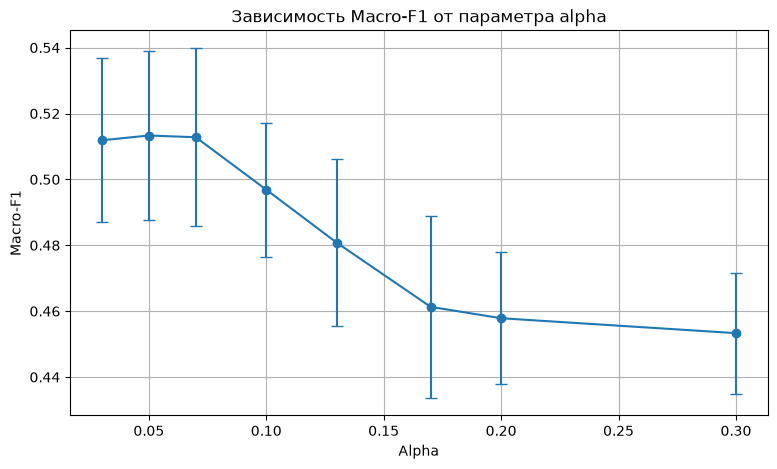

In [ ]:
results_nb = pd.DataFrame(grid_nb_fine.cv_results_)
results_nb = results_nb.sort_values('param_model__alpha')
alpha = results_nb['param_model__alpha'].astype(float)
mean_f1 = results_nb['mean_test_score']
std_f1 = results_nb['std_test_score']
plt.figure(figsize=(9, 5))
plt.errorbar(alpha, mean_f1, yerr=std_f1, fmt='-o', capsize=4)
plt.xlabel('Alpha')
plt.ylabel('Macro-F1')
plt.title('Зависимость Macro-F1 от параметра alpha')
plt.grid(True)
plt.show()


In [ ]:
param_grid_nb_tfidf = {'model__alpha': [0.1], 'model__fit_prior': [False], 'tfidf__ngram_range': [(1, 1), (1, 2)], 'tfidf__sublinear_tf': [False, True]}
grid_nb_tfidf = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=param_grid_nb_tfidf,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
)
grid_nb_tfidf.fit(X_train, y_train, groups=train_groups)
print('Лучшие параметры:', grid_nb_tfidf.best_params_)
print('Лучший средний Macro-F1:', grid_nb_tfidf.best_score_)


Лучшие параметры: {'model__alpha': 0.1, 'model__fit_prior': False, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Лучший средний Macro-F1: 0.5399455159942359


In [ ]:
results_tfidf = pd.DataFrame(grid_nb_tfidf.cv_results_)
display(results_tfidf[['param_tfidf__ngram_range', 'param_tfidf__sublinear_tf', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False))


,param_tfidf__ngram_range,param_tfidf__sublinear_tf,mean_test_score,std_test_score
3,"(1, 2)",True,0.539946,0.025177
2,"(1, 2)",False,0.522602,0.029589
1,"(1, 1)",True,0.502091,0.032173
0,"(1, 1)",False,0.496872,0.020285


In [ ]:
best_nb = grid_nb_tfidf.best_estimator_
y_pred_nb = cross_val_predict(best_nb, X_train, y_train, groups=train_groups, cv=cv, n_jobs=-1)
print('Accuracy:', accuracy_score(y_train, y_pred_nb))
print('Macro-F1:', f1_score(y_train, y_pred_nb, average='macro'))
print(classification_report(y_train, y_pred_nb, zero_division=0))


Accuracy: 0.6279166666666667
Macro-F1: 0.5407593739250086

Classification Report:
              precision    recall  f1-score   support

    negative       0.55      0.59      0.57       738
     neutral       0.75      0.69      0.72      1419
    positive       0.30      0.37      0.33       243

    accuracy                           0.63      2400
   macro avg       0.53      0.55      0.54      2400
weighted avg       0.64      0.63      0.63      2400



In [ ]:
bal_acc = balanced_accuracy_score(y_train, y_pred_nb)
print('Balanced Accuracy:', bal_acc)


Balanced Accuracy: 0.5510991797204271


In [ ]:
original = y_train.value_counts(normalize=True)
scenarios = {'Исходное распределение': original.to_dict(), 'Равные доли классов': {'neutral': 1 / 3, 'negative': 1 / 3, 'positive': 1 / 3}, 'Меньше neutral': {'neutral': 0.2, 'negative': 0.4, 'positive': 0.4}}
results_shift = []
for name, proportions in scenarios.items():
    weights = y_train.map({cls: proportions[cls] / original[cls] for cls in original.index})
    results_shift.append({'Сценарий': name, 'Accuracy': accuracy_score(y_train, y_pred_nb, sample_weight=weights), 'Balanced Accuracy': balanced_accuracy_score(y_train, y_pred_nb, sample_weight=weights), 'Macro-F1': f1_score(y_train, y_pred_nb, average='macro', sample_weight=weights)})
display(pd.DataFrame(results_shift).round(4))


,Сценарий,Accuracy,Balanced Accuracy,Macro-F1
0,Исходное распределение,0.6279,0.5511,0.5408
1,Равные доли классов,0.5511,0.5511,0.5445
2,Меньше neutral,0.5226,0.5511,0.5161


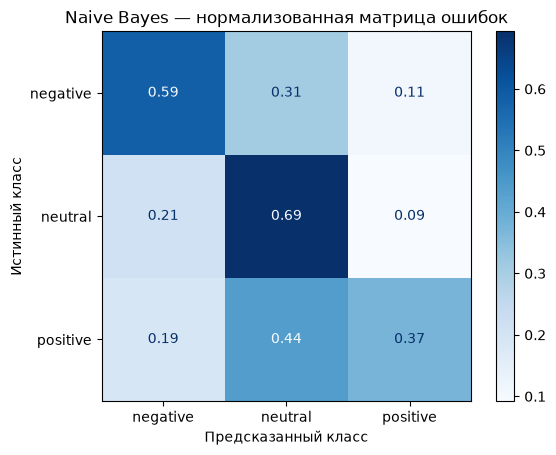

In [ ]:
classes = ['negative', 'neutral', 'positive']
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_nb, labels=classes, normalize='true', cmap='Blues', values_format='.2f')
plt.title('Naive Bayes — нормализованная матрица ошибок')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()


In [ ]:
TfidfVectorizer(max_features=10000, min_df=2, max_df=0.95, ngram_range=(1, 2), sublinear_tf=True)
MultinomialNB(alpha=0.1, fit_prior=False)


,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",0.1
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",False
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


посмотрим, что будет при других долях классов

### логистическая регрессия

In [ ]:
lr_pipeline = Pipeline([('tfidf', TfidfVectorizer(max_features=10000, min_df=2, max_df=0.95, ngram_range=(1, 2), sublinear_tf=True)), ('model', LogisticRegression(C=1.0, class_weight=None, max_iter=1000, random_state=42))])
lr_scores = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
)
print('Macro-F1 на каждой части кросс-валидации:', lr_scores)
print('Средний Macro-F1:', lr_scores.mean())
print('Стандартное отклонение:', lr_scores.std())


Macro-F1 на каждой части кросс-валидации: [0.50242903 0.50843461 0.54914608 0.50377448 0.49045139]
Средний Macro-F1: 0.5108471180872349
Стандартное отклонение: 0.020047459543018096


In [ ]:
lr_balanced_pipeline = clone(lr_pipeline)
lr_balanced_pipeline.set_params(model__class_weight='balanced')
lr_balanced_scores = cross_val_score(
    lr_balanced_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
)
print('Macro-F1 на каждой части:', lr_balanced_scores)
print('Средний Macro-F1:', lr_balanced_scores.mean())
print('Стандартное отклонение:', lr_balanced_scores.std())


Macro-F1 на каждой части: [0.61689142 0.62248862 0.6153812  0.61456972 0.56110574]
Средний Macro-F1: 0.606087339426489
Стандартное отклонение: 0.02266010068552442


In [ ]:
param_grid_lr = {'model__C': [0.1, 0.3, 1.0, 3.0, 10.0]}
grid_lr = GridSearchCV(
    estimator=lr_balanced_pipeline,
    param_grid=param_grid_lr,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
)
grid_lr.fit(X_train, y_train, groups=train_groups)
print('Лучшие параметры:', grid_lr.best_params_)
print('Лучший средний Macro-F1:', grid_lr.best_score_)
results_lr = pd.DataFrame(grid_lr.cv_results_)
display(results_lr[['param_model__C', 'mean_test_score', 'std_test_score']].sort_values('param_model__C'))


Лучшие параметры: {'model__C': 3.0}
Лучший средний Macro-F1: 0.6088966378179966


,param_model__C,mean_test_score,std_test_score
0,0.1,0.562686,0.025682
1,0.3,0.578788,0.025373
2,1.0,0.606087,0.022660
3,3.0,0.608897,0.021018
4,10.0,0.596777,0.025781


In [ ]:
best_lr = grid_lr.best_estimator_
y_pred_lr = cross_val_predict(best_lr, X_train, y_train, groups=train_groups, cv=cv, n_jobs=-1)
print('Accuracy:', accuracy_score(y_train, y_pred_lr))
print('Balanced Accuracy:', balanced_accuracy_score(y_train, y_pred_lr))
print('Macro-F1:', f1_score(y_train, y_pred_lr, average='macro'))
print(classification_report(y_train, y_pred_lr, zero_division=0))


Accuracy: 0.7016666666666667
Balanced Accuracy: 0.5963097286598894
Macro-F1: 0.609312830279627

Classification Report:
              precision    recall  f1-score   support

    negative       0.64      0.62      0.63       738
     neutral       0.76      0.80      0.78      1419
    positive       0.49      0.37      0.42       243

    accuracy                           0.70      2400
   macro avg       0.63      0.60      0.61      2400
weighted avg       0.69      0.70      0.70      2400



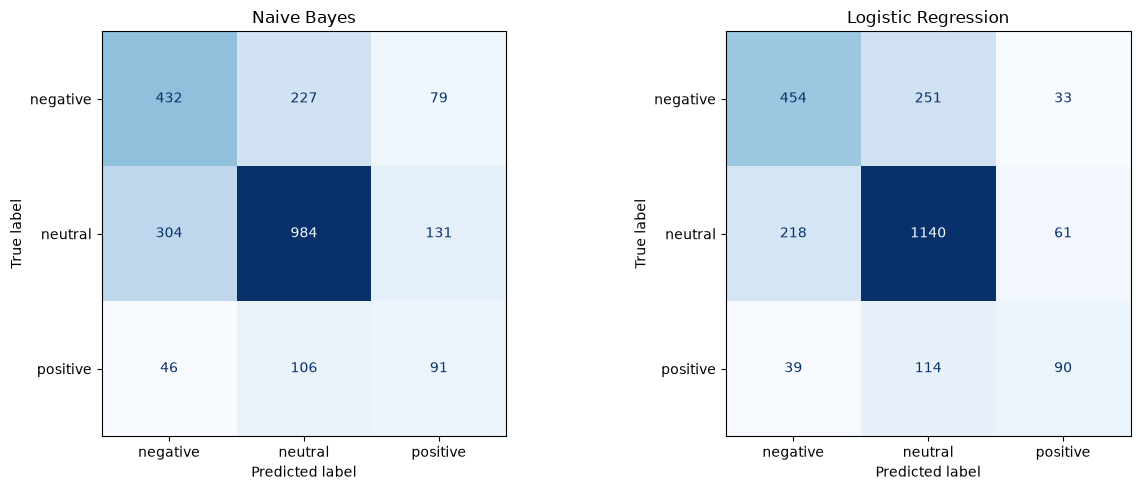

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
classes = ['negative', 'neutral', 'positive']
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_nb, labels=classes, cmap='Blues', values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title('Naive Bayes')
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_lr, labels=classes, cmap='Blues', values_format='d', ax=axes[1], colorbar=False)
axes[1].set_title('Logistic Regression')
plt.tight_layout()
plt.show()


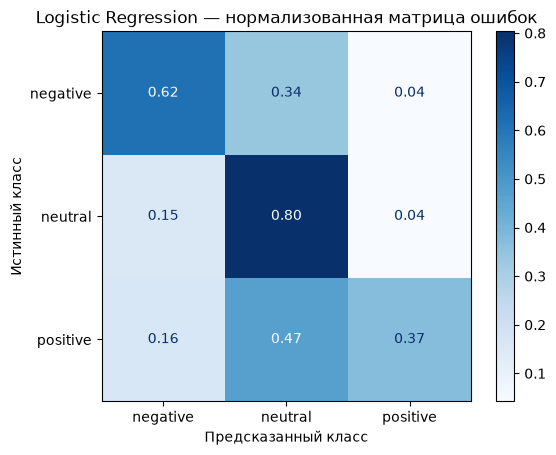

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_lr, labels=classes, normalize='true', cmap='Blues', values_format='.2f')
plt.title('Logistic Regression — нормализованная матрица ошибок')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()


In [ ]:
results_shift_lr = []
for name, proportions in scenarios.items():
    weights = y_train.map({cls: proportions[cls] / original[cls] for cls in original.index})
    results_shift_lr.append({'Сценарий': name, 'Accuracy': accuracy_score(y_train, y_pred_lr, sample_weight=weights), 'Balanced Accuracy': balanced_accuracy_score(y_train, y_pred_lr, sample_weight=weights), 'Macro-F1': f1_score(y_train, y_pred_lr, average='macro', sample_weight=weights)})
display(pd.DataFrame(results_shift_lr).round(4))


,Сценарий,Accuracy,Balanced Accuracy,Macro-F1
0,Исходное распределение,0.7017,0.5963,0.6093
1,Равные доли классов,0.5963,0.5963,0.5869
2,Меньше neutral,0.5549,0.5963,0.5498


### svm

In [ ]:
svm_pipeline = Pipeline([('tfidf', TfidfVectorizer(max_features=10000, min_df=2, max_df=0.95, ngram_range=(1, 2), sublinear_tf=True)), ('model', LinearSVC(C=1.0, class_weight=None, max_iter=5000, random_state=42))])
svm_scores = cross_val_score(
    svm_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
)
print('Macro-F1 на каждой части кросс-валидации:', svm_scores)
print('Средний Macro-F1:', svm_scores.mean())
print('Стандартное отклонение:', svm_scores.std())


Macro-F1 на каждой части кросс-валидации: [0.59003066 0.54738321 0.61617442 0.56475786 0.54525368]
Средний Macro-F1: 0.5727199625207683
Стандартное отклонение: 0.027009972063869767


In [ ]:
svm_balanced_pipeline = clone(svm_pipeline)
svm_balanced_pipeline.set_params(model__class_weight='balanced')
svm_balanced_scores = cross_val_score(
    svm_balanced_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
)
print('Macro-F1 на каждой части:', svm_balanced_scores)
print('Средний Macro-F1:', svm_balanced_scores.mean())
print('Стандартное отклонение:', svm_balanced_scores.std())


Macro-F1 на каждой части: [0.62757902 0.57158995 0.59693607 0.60611441 0.55847912]
Средний Macro-F1: 0.5921397138576249
Стандартное отклонение: 0.024615318030629177


In [ ]:
param_grid_svm = {'model__C': [0.1, 0.3, 1.0, 3.0, 10.0]}
grid_svm = GridSearchCV(
    estimator=svm_balanced_pipeline,
    param_grid=param_grid_svm,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
)
grid_svm.fit(X_train, y_train, groups=train_groups)
print('Лучшие параметры:', grid_svm.best_params_)
print('Лучший средний Macro-F1:', grid_svm.best_score_)
results_svm = pd.DataFrame(grid_svm.cv_results_)
display(results_svm[['param_model__C', 'mean_test_score', 'std_test_score']].sort_values('param_model__C'))


Лучшие параметры: {'model__C': 0.3}
Лучший средний Macro-F1: 0.6053464735574833


,param_model__C,mean_test_score,std_test_score
0,0.1,0.588920,0.022994
1,0.3,0.605346,0.018261
2,1.0,0.592140,0.024615
3,3.0,0.573302,0.024533
4,10.0,0.562345,0.026310


In [ ]:
best_svm = grid_svm.best_estimator_
y_pred_svm = cross_val_predict(best_svm, X_train, y_train, groups=train_groups, cv=cv, n_jobs=-1)
print('Accuracy:', accuracy_score(y_train, y_pred_svm))
print('Balanced Accuracy:', balanced_accuracy_score(y_train, y_pred_svm))
print('Macro-F1:', f1_score(y_train, y_pred_svm, average='macro'))
print(classification_report(y_train, y_pred_svm, zero_division=0))


Accuracy: 0.7141666666666666
Balanced Accuracy: 0.5788814314160421
Macro-F1: 0.6060848682257275

Classification Report:
              precision    recall  f1-score   support

    negative       0.67      0.58      0.62       738
     neutral       0.74      0.86      0.79      1419
    positive       0.61      0.30      0.41       243

    accuracy                           0.71      2400
   macro avg       0.67      0.58      0.61      2400
weighted avg       0.70      0.71      0.70      2400



In [ ]:
results_shift_svm = []
for name, proportions in scenarios.items():
    weights = y_train.map({cls: proportions[cls] / original[cls] for cls in original.index})
    results_shift_svm.append({'Сценарий': name, 'Accuracy': accuracy_score(y_train, y_pred_svm, sample_weight=weights), 'Balanced Accuracy': balanced_accuracy_score(y_train, y_pred_svm, sample_weight=weights), 'Macro-F1': f1_score(y_train, y_pred_svm, average='macro', sample_weight=weights)})
display(pd.DataFrame(results_shift_svm).round(4))


,Сценарий,Accuracy,Balanced Accuracy,Macro-F1
0,Исходное распределение,0.7142,0.5789,0.6061
1,Равные доли классов,0.5789,0.5789,0.5617
2,Меньше neutral,0.5234,0.5789,0.5187


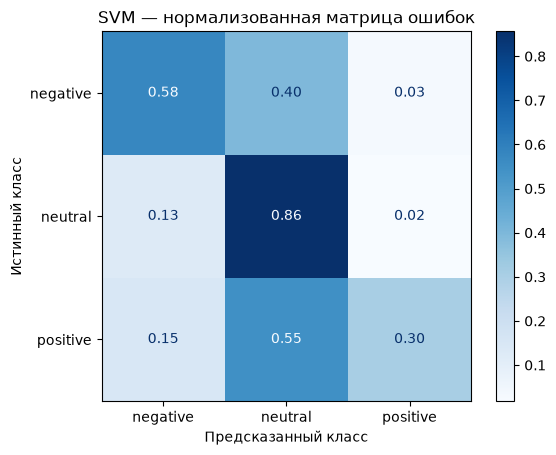

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_svm, labels=classes, normalize='true', cmap='Blues', values_format='.2f')
plt.title('SVM — нормализованная матрица ошибок')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()


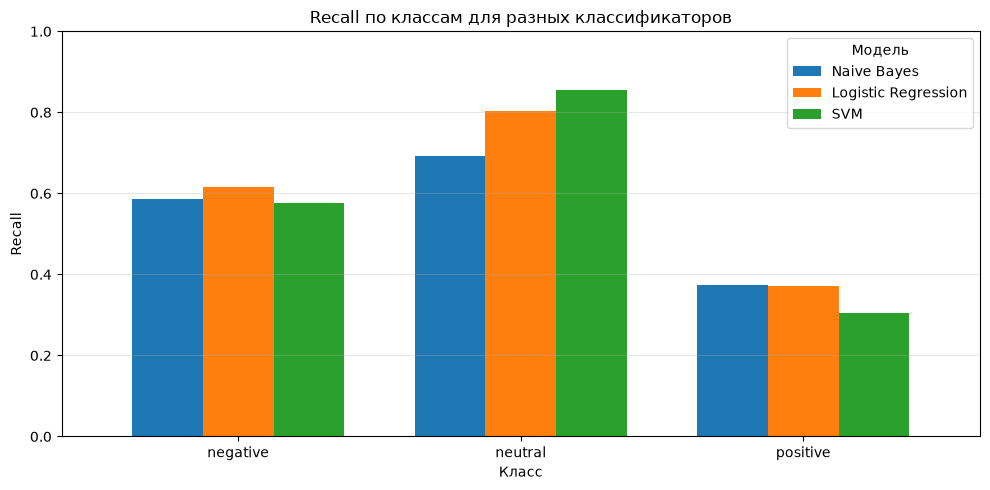

In [ ]:
recall_data = pd.DataFrame(
    {'Naive Bayes': recall_score(y_train, y_pred_nb, labels=classes, average=None), 'Logistic Regression': recall_score(y_train, y_pred_lr, labels=classes, average=None), 'SVM': recall_score(y_train, y_pred_svm, labels=classes, average=None)},
    index=classes,
)
ax = recall_data.plot(kind='bar', figsize=(10, 5), rot=0, width=0.75)
plt.title('Recall по классам для разных классификаторов')
plt.xlabel('Класс')
plt.ylabel('Recall')
plt.ylim(0, 1)
plt.legend(title='Модель')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


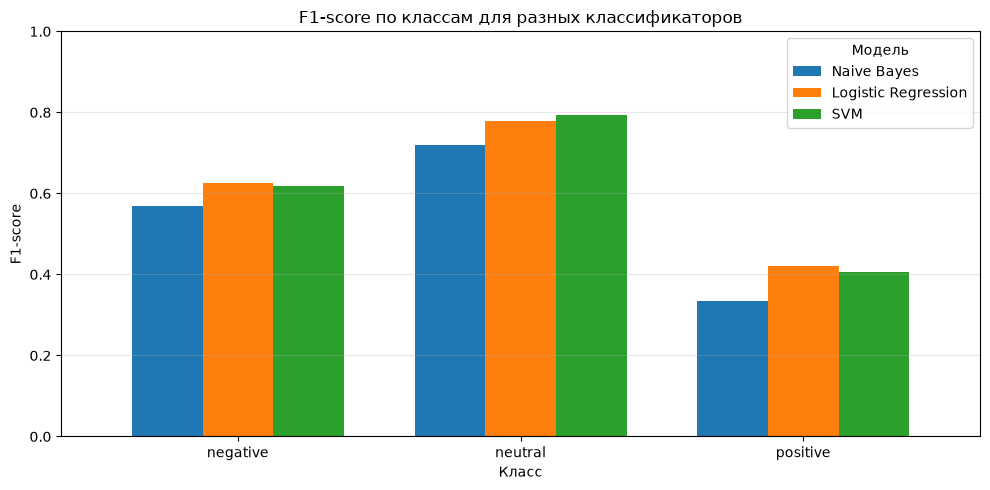

In [ ]:
f1_data = pd.DataFrame(
    {'Naive Bayes': f1_score(y_train, y_pred_nb, labels=classes, average=None), 'Logistic Regression': f1_score(y_train, y_pred_lr, labels=classes, average=None), 'SVM': f1_score(y_train, y_pred_svm, labels=classes, average=None)},
    index=classes,
)
ax = f1_data.plot(kind='bar', figsize=(10, 5), rot=0, width=0.75)
plt.title('F1-score по классам для разных классификаторов')
plt.xlabel('Класс')
plt.ylabel('F1-score')
plt.ylim(0, 1)
plt.legend(title='Модель')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


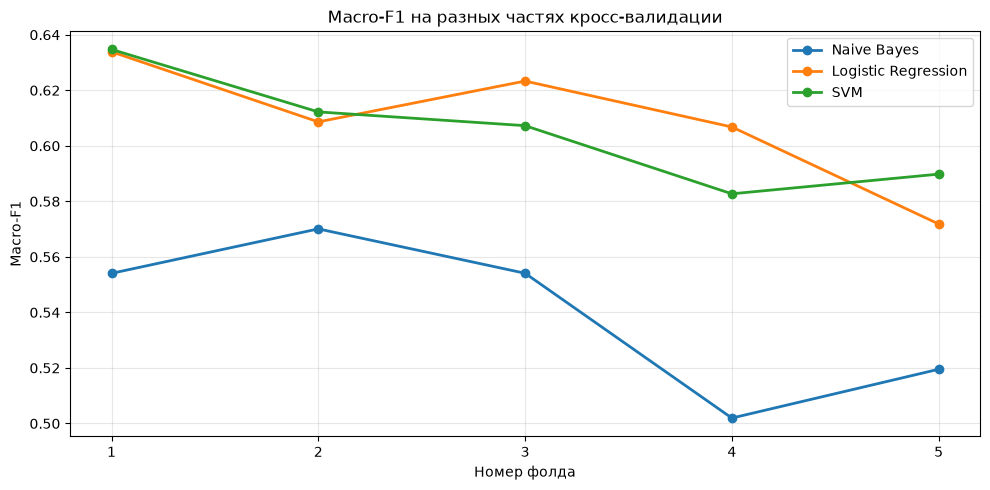

In [ ]:
grids = {'Naive Bayes': grid_nb_tfidf, 'Logistic Regression': grid_lr, 'SVM': grid_svm}
plt.figure(figsize=(10, 5))
for name, grid in grids.items():
    best_idx = grid.best_index_
    scores = [grid.cv_results_[f'split{i}_test_score'][best_idx] for i in range(5)]
    plt.plot(range(1, 6), scores, marker='o', linewidth=2, label=name)
plt.title('Macro-F1 на разных частях кросс-валидации')
plt.xlabel('Номер фолда')
plt.ylabel('Macro-F1')
plt.xticks(range(1, 6))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


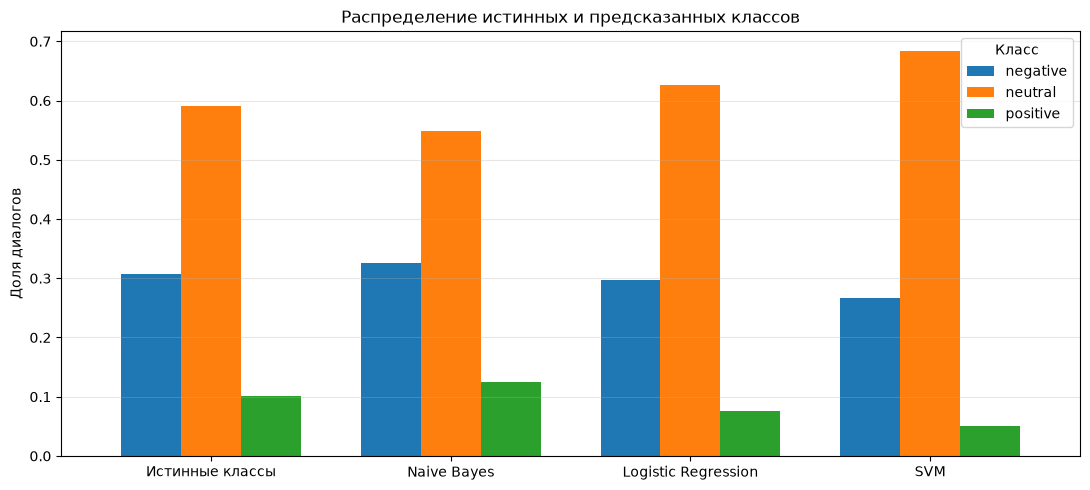

In [ ]:
predictions_df = pd.DataFrame({'Истинные классы': pd.Series(y_train).reset_index(drop=True), 'Naive Bayes': pd.Series(y_pred_nb), 'Logistic Regression': pd.Series(y_pred_lr), 'SVM': pd.Series(y_pred_svm)})
class_distribution = predictions_df.apply(lambda col: col.value_counts(normalize=True)).reindex(classes).fillna(0)
ax = class_distribution.T.plot(kind='bar', figsize=(11, 5), rot=0, width=0.75)
plt.title('Распределение истинных и предсказанных классов')
plt.xlabel('')
plt.ylabel('Доля диалогов')
plt.legend(title='Класс')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
C1_values = [0.1, 0.3, 1.0]
C2_values = [0.1, 0.3, 1.0]
two_stage_classes = np.array(['negative', 'neutral', 'positive'])
two_stage_y = np.asarray(y_train)
two_stage_texts = np.asarray(X_train)
two_stage_groups = np.asarray(train_groups)
two_stage_vectorizer_template = TfidfVectorizer(
    max_features=10000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
two_stage_fold_scores = {(c1, c2): [] for c1 in C1_values for c2 in C2_values}
two_stage_oof = {pair: np.full(len(two_stage_y), '', dtype=object) for pair in two_stage_fold_scores}
for fold_number, (fit_idx, val_idx) in enumerate(cv.split(two_stage_texts, two_stage_y, groups=two_stage_groups), start=1):
    fold_vectorizer = clone(two_stage_vectorizer_template)
    fold_X_fit = fold_vectorizer.fit_transform(two_stage_texts[fit_idx])
    fold_X_val = fold_vectorizer.transform(two_stage_texts[val_idx])
    fold_y_fit = two_stage_y[fit_idx]
    fold_y_stage1 = np.where(fold_y_fit == 'neutral', 'neutral', 'non-neutral')
    fold_non_neutral = fold_y_fit != 'neutral'
    stage1_predictions = {}
    stage2_predictions = {}
    for c1 in C1_values:
        fold_stage1 = LinearSVC(C=c1, class_weight='balanced', max_iter=5000, random_state=42)
        fold_stage1.fit(fold_X_fit, fold_y_stage1)
        stage1_predictions[c1] = fold_stage1.predict(fold_X_val)
    for c2 in C2_values:
        fold_stage2 = LinearSVC(C=c2, class_weight='balanced', max_iter=5000, random_state=42)
        fold_stage2.fit(fold_X_fit[fold_non_neutral], fold_y_fit[fold_non_neutral])
        stage2_predictions[c2] = fold_stage2.predict(fold_X_val)
    for (c1, c2), scores in two_stage_fold_scores.items():
        pred = np.full(len(val_idx), 'neutral', dtype=object)
        routed = stage1_predictions[c1] == 'non-neutral'
        pred[routed] = stage2_predictions[c2][routed]
        scores.append(f1_score(two_stage_y[val_idx], pred, labels=two_stage_classes, average='macro', zero_division=0))
        two_stage_oof[c1, c2][val_idx] = pred
two_stage_cv_results = pd.DataFrame([{'C1': c1, 'C2': c2, 'mean_macro_f1': np.mean(scores), 'std_macro_f1': np.std(scores)} for (c1, c2), scores in two_stage_fold_scores.items()]).sort_values('mean_macro_f1', ascending=False, kind='stable').reset_index(drop=True)
display(two_stage_cv_results.round(4))
best_C1 = float(two_stage_cv_results.loc[0, 'C1'])
best_C2 = float(two_stage_cv_results.loc[0, 'C2'])
y_pred_two_stage = two_stage_oof[best_C1, best_C2]
print(f'Лучшие параметры: C1={best_C1}, C2={best_C2}')
print('Лучший средний Macro-F1:', two_stage_cv_results.loc[0, 'mean_macro_f1'])
print('\nAccuracy:', accuracy_score(two_stage_y, y_pred_two_stage))
print('Balanced Accuracy:', balanced_accuracy_score(two_stage_y, y_pred_two_stage))
print('Macro-F1:', f1_score(two_stage_y, y_pred_two_stage, average='macro'))
print(classification_report(two_stage_y, y_pred_two_stage, labels=two_stage_classes, zero_division=0))
comparison_two_stage = pd.DataFrame([{'Модель': name, 'Accuracy': accuracy_score(two_stage_y, pred), 'Balanced Accuracy': balanced_accuracy_score(two_stage_y, pred), 'Macro-F1': f1_score(two_stage_y, pred, average='macro'), 'Recall positive': recall_score(two_stage_y, pred, labels=['positive'], average=None, zero_division=0)[0]} for name, pred in {'Naive Bayes': y_pred_nb, 'Logistic Regression': y_pred_lr, 'SVM': y_pred_svm, 'Two-stage SVM': y_pred_two_stage}.items()]).set_index('Модель')
display(comparison_two_stage.round(4))
two_stage_vectorizer = clone(two_stage_vectorizer_template)
two_stage_X_train = two_stage_vectorizer.fit_transform(two_stage_texts)
stage1 = LinearSVC(C=best_C1, class_weight='balanced', max_iter=5000, random_state=42)
stage2 = LinearSVC(C=best_C2, class_weight='balanced', max_iter=5000, random_state=42)
stage1.fit(two_stage_X_train, np.where(two_stage_y == 'neutral', 'neutral', 'non-neutral'))
non_neutral_train_mask = two_stage_y != 'neutral'
stage2.fit(two_stage_X_train[non_neutral_train_mask], two_stage_y[non_neutral_train_mask])

def predict_two_stage(texts):
    """Предсказания трёх классов для новых текстов."""
    texts = list(texts)
    if not texts:
        return np.empty(0, dtype=object)
    features = two_stage_vectorizer.transform(texts)
    pred_stage1 = stage1.predict(features)
    pred = np.full(len(texts), 'neutral', dtype=object)
    non_neutral_mask = pred_stage1 == 'non-neutral'
    if non_neutral_mask.any():
        pred[non_neutral_mask] = stage2.predict(features[non_neutral_mask])
    return pred
ConfusionMatrixDisplay.from_predictions(two_stage_y, y_pred_two_stage, labels=two_stage_classes, normalize='true', cmap='Blues', values_format='.2f')
plt.title('Two-stage LinearSVC')
plt.show()


In [ ]:
hierarchy_classes = np.array(['negative', 'neutral', 'positive'])
hierarchy_inner_splits = 3
hierarchy_outer_cv = cv
hierarchy_train_dialogs = df_reaction.iloc[train_idx].reset_index(drop=True)
hierarchy_y = hierarchy_train_dialogs['reaction'].to_numpy()
hierarchy_groups = hierarchy_train_dialogs['group'].to_numpy()

def make_reaction_pairs(dialogs):
    records = []
    for dialog_pos, row in enumerate(dialogs.itertuples(index=False)):
        users = [i for i, turn in enumerate(row.turns) if turn['role'] == 'user']
        annotations = row.labels['user_turns']
        if len(users) != len(annotations):
            raise ValueError('Количество пользовательских сообщений и меток различается')
        for user_pos, (turn_idx, annotation) in enumerate(zip(users, annotations)):
            reaction = annotation.get('reaction')
            if reaction is None:
                continue
            if turn_idx == 0 or row.turns[turn_idx - 1]['role'] != 'assistant':
                raise ValueError('У размеченной реакции нет предыдущего ответа ассистента')
            records.append({'dialog_pos': dialog_pos, 'user': row.turns[turn_idx]['text'], 'assistant': row.turns[turn_idx - 1]['text'], 'reaction': reaction, 'position': user_pos / max(len(users) - 1, 1)})
    return pd.DataFrame(records)

def make_pair_reaction_model():

    def word():
        return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=10000, sublinear_tf=True, dtype=np.float32)

    def char():
        return TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, max_features=10000, sublinear_tf=True, dtype=np.float32)
    return Pipeline([('features', ColumnTransformer([('user_word', word(), 'user'), ('user_char', char(), 'user'), ('assistant_word', word(), 'assistant'), ('assistant_char', char(), 'assistant')], sparse_threshold=1.0)), ('model', LogisticRegression(C=1.0, class_weight='balanced', max_iter=1500, random_state=42))])

def aligned_reaction_proba(model, texts):
    probability = model.predict_proba(texts)
    order = [list(model.classes_).index(c) for c in hierarchy_classes]
    return probability[:, order]

def aggregate_reaction_proba(pairs, probabilities, n_dialogs):
    ids = pairs['dialog_pos'].to_numpy(dtype=np.int64)
    positions = pairs['position'].to_numpy(dtype=np.float64)
    p = np.asarray(probabilities, dtype=np.float64)
    if p.shape != (len(ids), len(hierarchy_classes)) or not np.isfinite(p).all():
        raise ValueError('Некорректные вероятности реакций')
    order = np.argsort(ids, kind='stable')
    ids, positions, p = (ids[order], positions[order], p[order])
    counts = np.bincount(ids, minlength=n_dialogs)
    if len(counts) != n_dialogs or (counts == 0).any():
        raise ValueError('Диалог не содержит реакций или имеет неверный индекс')
    starts = np.r_[0, np.cumsum(counts)[:-1]]
    ends = starts + counts - 1
    hard = p.argmax(axis=1)
    means = np.add.reduceat(p, starts, axis=0) / counts[:, None]
    maxima = np.maximum.reduceat(p, starts, axis=0)
    variances = np.add.reduceat((p - means[ids]) ** 2, starts, axis=0) / counts[:, None]
    previous = np.maximum(starts, ends - 1)
    last2 = (p[ends] + p[previous]) / 2
    last2[counts == 1] = p[ends[counts == 1]]
    row = {'n_reactions': counts}
    for k, name in enumerate(hierarchy_classes):
        selected = hard == k
        selected_counts = np.bincount(ids, weights=selected, minlength=n_dialogs)
        peak_candidates = np.where(p[:, k] == maxima[ids, k], np.arange(len(ids)), len(ids))
        peak_indices = np.minimum.reduceat(peak_candidates, starts)
        row.update({f'{name}_mean': means[:, k], f'{name}_max': maxima[:, k], f'{name}_std': np.sqrt(variances[:, k]), f'{name}_first': p[starts, k], f'{name}_last': p[ends, k], f'{name}_last2_mean': last2[:, k], f'{name}_last_minus_first': p[ends, k] - p[starts, k], f'{name}_count': selected_counts, f'{name}_share': selected_counts / counts, f'{name}_peak_position': positions[peak_indices]})
    non_neutral = hard != 1
    nn_counts = np.bincount(ids, weights=non_neutral, minlength=n_dialogs)
    row['non_neutral_count'] = nn_counts
    row['non_neutral_share'] = nn_counts / counts
    row['last_non_neutral_position'] = np.maximum.reduceat(np.where(non_neutral, positions, -1), starts)
    changes = np.r_[False, (ids[1:] == ids[:-1]) & (hard[1:] != hard[:-1])]
    row['reaction_change_share'] = np.bincount(ids, weights=changes, minlength=n_dialogs) / np.maximum(counts - 1, 1)
    entropy = -np.sum(p * np.log(np.clip(p, 1e-12, 1)), axis=1)
    row['mean_entropy'] = np.add.reduceat(entropy, starts) / counts
    return pd.DataFrame(row)

def fit_hierarchy_features(fit_dialogs, predict_dialogs=None, seed=42):
    pairs = make_reaction_pairs(fit_dialogs)
    oof = np.full((len(pairs), len(hierarchy_classes)), np.nan)
    fit_y = fit_dialogs['reaction'].to_numpy()
    fit_groups = fit_dialogs['group'].to_numpy()
    inner_cv = StratifiedGroupKFold(n_splits=hierarchy_inner_splits, shuffle=True, random_state=seed)
    for inner_number, (inner_fit, inner_val) in enumerate(inner_cv.split(fit_dialogs, fit_y, groups=fit_groups), start=1):
        pair_fit = pairs['dialog_pos'].isin(inner_fit).to_numpy()
        pair_val = pairs['dialog_pos'].isin(inner_val).to_numpy()
        model = make_pair_reaction_model()
        model.fit(pairs.loc[pair_fit, ['user', 'assistant']], pairs.loc[pair_fit, 'reaction'])
        oof[pair_val] = aligned_reaction_proba(model, pairs.loc[pair_val, ['user', 'assistant']])
    if not np.isfinite(oof).all():
        raise ValueError('Не все реплики получили OOF-вероятности')
    train_features = aggregate_reaction_proba(pairs, oof, len(fit_dialogs))
    pair_model = make_pair_reaction_model()
    pair_model.fit(pairs[['user', 'assistant']], pairs['reaction'])
    predict_features = None
    if predict_dialogs is not None:
        prediction_pairs = make_unlabeled_pairs(predict_dialogs)
        proba = aligned_reaction_proba(pair_model, prediction_pairs[['user', 'assistant']])
        predict_features = aggregate_reaction_proba(prediction_pairs, proba, len(predict_dialogs))
    return (train_features, predict_features, pair_model)

def make_unlabeled_pairs(dialogs):
    records = []
    for dialog_pos, row in enumerate(dialogs.itertuples(index=False)):
        users = [i for i, turn in enumerate(row.turns) if turn['role'] == 'user']
        for user_pos, turn_idx in enumerate(users):
            if turn_idx > 0 and row.turns[turn_idx - 1]['role'] == 'assistant':
                records.append({'dialog_pos': dialog_pos, 'user': row.turns[turn_idx]['text'], 'assistant': row.turns[turn_idx - 1]['text'], 'position': user_pos / max(len(users) - 1, 1)})
    return pd.DataFrame(records)

def make_dialog_aggregators():
    return {'Hierarchy LR': Pipeline([('scale', StandardScaler()), ('model', LogisticRegression(C=1.0, max_iter=1500, random_state=42))]), 'Hierarchy HGB': HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=7, min_samples_leaf=20, l2_regularization=1.0, early_stopping=False, random_state=42)}
hierarchy_oof_predictions = {name: np.full(len(hierarchy_y), '', dtype=object) for name in make_dialog_aggregators()}
hierarchy_fold_scores = {name: [] for name in hierarchy_oof_predictions}
for fold_number, (fit_idx, val_idx) in enumerate(hierarchy_outer_cv.split(hierarchy_train_dialogs, hierarchy_y, hierarchy_groups), start=1):
    fit_dialogs = hierarchy_train_dialogs.iloc[fit_idx].reset_index(drop=True)
    val_dialogs = hierarchy_train_dialogs.iloc[val_idx].reset_index(drop=True)
    fit_features, val_features, _ = fit_hierarchy_features(fit_dialogs, val_dialogs)
    weights = compute_sample_weight('balanced', hierarchy_y[fit_idx])
    for name, model in make_dialog_aggregators().items():
        if isinstance(model, Pipeline):
            model.fit(fit_features, hierarchy_y[fit_idx], model__sample_weight=weights)
        else:
            model.fit(fit_features, hierarchy_y[fit_idx], sample_weight=weights)
        pred = model.predict(val_features)
        hierarchy_oof_predictions[name][val_idx] = pred
        score = f1_score(hierarchy_y[val_idx], pred, average='macro')
        hierarchy_fold_scores[name].append(score)
hierarchy_cv_table = pd.DataFrame({name: {'Mean CV Macro-F1': np.mean(scores), 'Std CV Macro-F1': np.std(scores)} for name, scores in hierarchy_fold_scores.items()}).T
display(hierarchy_cv_table.round(4))
best_hierarchy_name = hierarchy_cv_table['Mean CV Macro-F1'].idxmax()
hierarchy_comparison_predictions = {'Naive Bayes': y_pred_nb, 'Logistic Regression': y_pred_lr, 'SVM': y_pred_svm, **hierarchy_oof_predictions}
if 'y_pred_two_stage' in globals():
    hierarchy_comparison_predictions['Two-stage SVM'] = y_pred_two_stage
hierarchy_comparison = pd.DataFrame([{'Модель': name, 'Accuracy': accuracy_score(hierarchy_y, pred), 'Balanced Accuracy': balanced_accuracy_score(hierarchy_y, pred), 'Macro-F1': f1_score(hierarchy_y, pred, average='macro')} for name, pred in hierarchy_comparison_predictions.items()]).set_index('Модель')
display(hierarchy_comparison.round(4))
for name, pred in hierarchy_oof_predictions.items():
    print(f'\n{name}')
    print(classification_report(hierarchy_y, pred, labels=hierarchy_classes, zero_division=0))
hierarchy_final_features, _, hierarchy_pair_model = fit_hierarchy_features(hierarchy_train_dialogs)
hierarchy_dialog_models = make_dialog_aggregators()
for name, model in hierarchy_dialog_models.items():
    weights = compute_sample_weight('balanced', hierarchy_y)
    if isinstance(model, Pipeline):
        model.fit(hierarchy_final_features, hierarchy_y, model__sample_weight=weights)
    else:
        model.fit(hierarchy_final_features, hierarchy_y, sample_weight=weights)

def predict_hierarchy(dialogs, aggregator=None):
    """dialogs: DataFrame с turns; labels для предсказания не нужны."""
    if len(dialogs) == 0:
        return np.empty(0, dtype=object)
    pairs = make_unlabeled_pairs(dialogs.reset_index(drop=True))
    proba = aligned_reaction_proba(hierarchy_pair_model, pairs[['user', 'assistant']])
    features = aggregate_reaction_proba(pairs, proba, len(dialogs))
    name = best_hierarchy_name if aggregator is None else aggregator
    return hierarchy_dialog_models[name].predict(features)


Внешний фолд 1: обучение модели реплик
  Внутренний фолд 1/3
  Внутренний фолд 2/3
  Внутренний фолд 3/3
  Hierarchy LR: Macro-F1 0.6208
  Hierarchy HGB: Macro-F1 0.6354
Внешний фолд 2: обучение модели реплик
  Внутренний фолд 1/3
  Внутренний фолд 2/3
  Внутренний фолд 3/3
  Hierarchy LR: Macro-F1 0.6603
  Hierarchy HGB: Macro-F1 0.6136
Внешний фолд 3: обучение модели реплик
  Внутренний фолд 1/3
  Внутренний фолд 2/3
  Внутренний фолд 3/3
  Hierarchy LR: Macro-F1 0.6419
  Hierarchy HGB: Macro-F1 0.6177
Внешний фолд 4: обучение модели реплик
  Внутренний фолд 1/3
  Внутренний фолд 2/3
  Внутренний фолд 3/3
  Hierarchy LR: Macro-F1 0.6213
  Hierarchy HGB: Macro-F1 0.6360
Внешний фолд 5: обучение модели реплик
  Внутренний фолд 1/3
  Внутренний фолд 2/3
  Внутренний фолд 3/3
  Hierarchy LR: Macro-F1 0.5879
  Hierarchy HGB: Macro-F1 0.5979

Сравнение агрегаторов:


,Mean CV Macro-F1,Std CV Macro-F1
Hierarchy LR,0.6264,0.0242
Hierarchy HGB,0.6201,0.0143


,Accuracy,Balanced Accuracy,Macro-F1
Модель,,,
Naive Bayes,0.6279,0.5511,0.5408
Logistic Regression,0.7017,0.5963,0.6093
SVM,0.7142,0.5789,0.6061
Hierarchy LR,0.6846,0.6694,0.6267
Hierarchy HGB,0.6917,0.6289,0.6208



Hierarchy LR
              precision    recall  f1-score   support

    negative       0.63      0.68      0.66       738
     neutral       0.83      0.69      0.76      1419
    positive       0.37      0.63      0.47       243

    accuracy                           0.68      2400
   macro avg       0.61      0.67      0.63      2400
weighted avg       0.72      0.68      0.70      2400


Hierarchy HGB
              precision    recall  f1-score   support

    negative       0.62      0.63      0.63       738
     neutral       0.78      0.75      0.77      1419
    positive       0.44      0.50      0.47       243

    accuracy                           0.69      2400
   macro avg       0.61      0.63      0.62      2400
weighted avg       0.70      0.69      0.69      2400

Обучение финальной иерархической модели
  Внутренний фолд 1/3
  Внутренний фолд 2/3
  Внутренний фолд 3/3
Готово за 12.3 мин.


Отложенный тест: 600 диалогов
Основной агрегатор выбран по CV: Hierarchy LR


,Accuracy,Balanced Accuracy,Macro-F1,Precision positive,Recall positive
Модель,,,,,
Hierarchy LR,0.6883,0.6791,0.6328,0.3861,0.6500
Hierarchy HGB,0.6983,0.6516,0.6282,0.3951,0.5333



Отчёт основной модели:
              precision    recall  f1-score   support

    negative       0.61      0.70      0.65       185
     neutral       0.85      0.69      0.76       355
    positive       0.39      0.65      0.48        60

    accuracy                           0.69       600
   macro avg       0.62      0.68      0.63       600
weighted avg       0.73      0.69      0.70       600



Обученные модели сохранены: artifacts/hierarchy_final.joblib


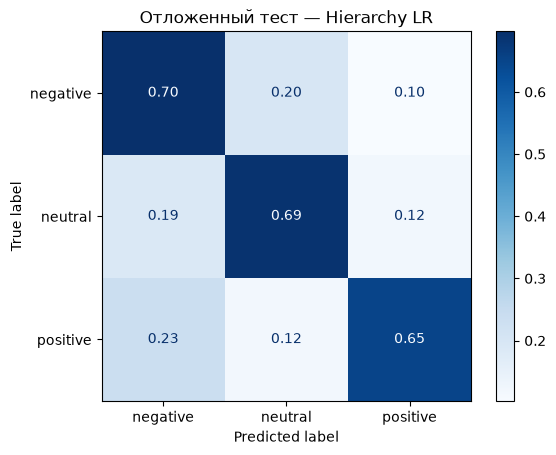

In [ ]:
required_final_variables = ['hierarchy_pair_model', 'hierarchy_dialog_models', 'best_hierarchy_name', 'predict_hierarchy', 'df_reaction', 'test_idx', 'train_idx']
missing_final_variables = [name for name in required_final_variables if name not in globals()]
if missing_final_variables:
    raise RuntimeError('Сначала выполните ячейку обучения: ' + ', '.join(missing_final_variables))
final_test_dialogs = df_reaction.iloc[test_idx].reset_index(drop=True)
final_test_y = final_test_dialogs['reaction'].to_numpy()
assert not set(df_reaction.iloc[train_idx]['group']) & set(final_test_dialogs['group'])
final_test_inputs = final_test_dialogs.drop(columns=['labels', 'reaction'], errors='ignore')
final_test_pairs = make_unlabeled_pairs(final_test_inputs)
final_test_probabilities = aligned_reaction_proba(
    hierarchy_pair_model,
    final_test_pairs[['user', 'assistant']],
)
final_test_features = aggregate_reaction_proba(
    final_test_pairs,
    final_test_probabilities,
    len(final_test_inputs),
)
final_test_predictions = {name: model.predict(final_test_features) for name, model in hierarchy_dialog_models.items()}
final_test_metrics = pd.DataFrame([{'Модель': name, 'Accuracy': accuracy_score(final_test_y, pred), 'Balanced Accuracy': balanced_accuracy_score(final_test_y, pred), 'Macro-F1': f1_score(final_test_y, pred, average='macro'), 'Precision positive': precision_score(final_test_y, pred, labels=['positive'], average=None, zero_division=0)[0], 'Recall positive': recall_score(final_test_y, pred, labels=['positive'], average=None, zero_division=0)[0]} for name, pred in final_test_predictions.items()]).set_index('Модель')
display(final_test_metrics.round(4))
print(classification_report(final_test_y, final_test_predictions[best_hierarchy_name], labels=hierarchy_classes, zero_division=0))
final_artifact_path = Path('artifacts/hierarchy_final.joblib')
final_artifact_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({'pair_model': hierarchy_pair_model, 'dialog_models': hierarchy_dialog_models, 'best_aggregator': best_hierarchy_name, 'classes': hierarchy_classes, 'feature_columns': list(final_test_features.columns), 'train_dialog_ids': df_reaction.iloc[train_idx]['dialog_id'].tolist(), 'test_dialog_ids': final_test_dialogs['dialog_id'].tolist(), 'sklearn_version': sklearn.__version__}, final_artifact_path)
ConfusionMatrixDisplay.from_predictions(final_test_y, final_test_predictions[best_hierarchy_name], labels=hierarchy_classes, normalize='true', cmap='Blues', values_format='.2f')
plt.title(f'Отложенный тест — {best_hierarchy_name}')
plt.show()


### правило разметки

сначала по настоящим реакциям: как из них получается метка диалога?

дальше фолды по диалогам, подбор внутри train. если модель учится на оценках другой модели, берём внутренние oof

In [ ]:
import experiments.reaction_experiments as reaction_experiments
experiment_groups = train_data['group'].to_numpy()
a_metrics, a_mixed_cases = reaction_experiments.run_a(train_data, experiment_groups)
all_oracle_sequences = reaction_experiments.oracle_sequences(df_reaction)
all_rule_predictions = np.array([reaction_experiments.last_non_neutral(sequence) for sequence in all_oracle_sequences])
all_rule_errors = int(np.sum(all_rule_predictions != df_reaction['reaction'].to_numpy()))
print(f'Проверка найденного правила на всех {len(df_reaction)} диалогах: ошибок {all_rule_errors}')
display(a_mixed_cases.head(12))


A: true reactions only; diagnostic oracle, not a text classifier
                     Accuracy  Balanced Accuracy  Macro-F1  Errors  Mixed accuracy
Method                                                                            
Last non-neutral       1.0000             1.0000    1.0000       0          1.0000
First non-neutral      0.9808             0.9608    0.9584      46          0.2203
Negative priority      0.9892             0.9643    0.9754      26          0.5593
Positive priority      0.9862             0.9851    0.9712      33          0.4407
Last reaction          0.8088             0.6676    0.7307     459          0.6780
Oracle tree depth 3    0.9967             0.9936    0.9927       8          0.8644
Oracle tree depth 5    0.9983             0.9954    0.9963       4          0.9322
Oracle LR              0.9979             0.9959    0.9954       5          0.9153
Mixed dialogues: 59
All 3000 dialogue rule errors: 0
  dialog_id                                         

### по отдельным репликам

размеченных реплик больше, попробуем учиться на них. сразу три класса или сначала neutral/non-neutral, потом знак

In [ ]:
with threadpool_limits(limits=1):
    (bcd_metrics, b_pair_metrics, d_mixed_metrics) = reaction_experiments.run_bcd(
        train_data,
        experiment_groups,
        n_splits=5,
        inner_splits=3,
    )
display(b_pair_metrics.round(4))
display(bcd_metrics.loc[bcd_metrics.index.str.startswith('B ')].round(4))


Outer fold 1/5
  Inner 1/3 done
  Inner 2/3 done
  Inner 3/3 done
  B equal direct: 0.6276
  B equal two-stage: 0.6331
  B user_focus direct: 0.6344
  B user_focus two-stage: 0.6435
  C auxiliary LR: 0.5484
  C auxiliary HGB: 0.6614
  D soft last rule: 0.6677
  D structural: 0.5947
  Fold seconds: 215.2
Outer fold 2/5
  Inner 1/3 done
  Inner 2/3 done
  Inner 3/3 done
  B equal direct: 0.6391
  B equal two-stage: 0.6137
  B user_focus direct: 0.6421
  B user_focus two-stage: 0.6220
  C auxiliary LR: 0.6207
  C auxiliary HGB: 0.6190
  D soft last rule: 0.5829
  D structural: 0.5988
  Fold seconds: 190.2
Outer fold 3/5
  Inner 1/3 done
  Inner 2/3 done
  Inner 3/3 done
  B equal direct: 0.6703
  B equal two-stage: 0.6459
  B user_focus direct: 0.6600
  B user_focus two-stage: 0.6387
  C auxiliary LR: 0.6975
  C auxiliary HGB: 0.6797
  D soft last rule: 0.6614
  D structural: 0.6754
  Fold seconds: 175.6
Outer fold 4/5
  Inner 1/3 done
  Inner 2/3 done
  Inner 3/3 done
  B equal direct: 0

### state и reason

разметка уже есть, попробуем и её использовать. на вход добавляем предсказания, не настоящие метки

In [ ]:
experiment_results_dir = Path('artifacts/reaction_experiments')
experiment_summary_path = experiment_results_dir / 'BCD_summary.json'
bcd_metrics = pd.read_csv(experiment_results_dir / 'BCD_dialog_metrics.csv', index_col=0)
display(bcd_metrics.loc[['B user_focus direct', 'C auxiliary LR', 'C auxiliary HGB']].round(4))
experiment_summary = json.loads(experiment_summary_path.read_text())
for name in ['C auxiliary LR', 'C auxiliary HGB']:
    print(name)
    display(pd.DataFrame(experiment_summary['reports'][name]).T.round(4))


                     Accuracy  Balanced Accuracy  Macro-F1  Mean CV Macro-F1  Std CV Macro-F1
Method                                                                                       
B user_focus direct    0.6958             0.6593    0.6300            0.6296           0.0221
C auxiliary LR         0.6642             0.6131    0.5840            0.5903           0.0677
C auxiliary HGB        0.7171             0.6238    0.6423            0.6409           0.0345
C auxiliary LR
              precision  recall  f1-score    support
negative         0.6388  0.5393    0.5849   738.0000
neutral          0.7867  0.7484    0.7671  1419.0000
positive         0.3138  0.5514    0.4000   243.0000
accuracy         0.6642  0.6642    0.6642     0.6642
macro avg        0.5798  0.6131    0.5840  2400.0000
weighted avg     0.6933  0.6642    0.6739  2400.0000
C auxiliary HGB
              precision  recall  f1-score    support
negative         0.6542  0.5691    0.6087   738.0000
neutral          0.757

### собираем диалог

мягкое правило последней реакции или отдельная модель для случаев с обоими знаками

In [ ]:
experiment_results_dir = Path('artifacts/reaction_experiments')
bcd_metrics = pd.read_csv(experiment_results_dir / 'BCD_dialog_metrics.csv', index_col=0)
d_mixed_metrics = pd.read_csv(experiment_results_dir / 'D_mixed_metrics.csv', index_col=0)
display(bcd_metrics.loc[['B user_focus direct', 'D soft last rule', 'D structural']].round(4))
display(d_mixed_metrics.round(4))
display(bcd_metrics.sort_values('Mean CV Macro-F1', ascending=False).round(4))


                     Accuracy  Balanced Accuracy  Macro-F1  Mean CV Macro-F1  Std CV Macro-F1
Method                                                                                       
B user_focus direct    0.6958             0.6593    0.6300            0.6296           0.0221
D soft last rule       0.6975             0.6167    0.6355            0.6338           0.0338
D structural           0.6983             0.6056    0.6024            0.6044           0.0370
                        Mixed accuracy  Mixed count
Method                                             
B equal direct                  0.5593           59
B equal two-stage               0.5424           59
B user_focus direct             0.5254           59
B user_focus two-stage          0.5085           59
C auxiliary LR                  0.5593           59
C auxiliary HGB                 0.5085           59
D soft last rule                0.6271           59
D structural                    0.5424           59

### svm + fca

добавим правила, сверху lr. число правил ограничиваем, иначе долго

In [ ]:
import experiments.fca_reactions as fca_reactions
fca_groups = train_data['group'].to_numpy()
fca_results_dir = fca_reactions.RESULT_DIR
fca_summary_path = fca_results_dir / 'summary.json'
(fca_dialog_metrics, fca_pair_metrics, fca_mixed_metrics, fca_final_model) = fca_reactions.run_experiment(
    train_data,
    fca_groups,
    n_splits=5,
    inner_splits=3,
    train_final=True,
)
display(fca_pair_metrics.round(4))
display(fca_dialog_metrics.round(4))
display(fca_mixed_metrics.round(4))
previous_results_path = Path('artifacts/reaction_experiments/BCD_dialog_metrics.csv')
if previous_results_path.exists():
    previous_fca_comparison = pd.read_csv(previous_results_path, index_col=0).loc[['B equal direct', 'C auxiliary HGB', 'D soft last rule']]
    display(pd.concat([previous_fca_comparison, fca_dialog_metrics])[['Mean CV Macro-F1', 'Std CV Macro-F1', 'Accuracy']].round(4))
fca_final_rules = pd.read_csv(fca_results_dir / 'final_rules.csv')
display(fca_final_rules.groupby('class', sort=False).head(5))


FCA outer fold 1/5
  Inner 1/3: concepts=766, rules=48, svm_iterations=11
  Inner 2/3: concepts=960, rules=48, svm_iterations=8
  Inner 3/3: concepts=918, rules=50, svm_iterations=11
  SVC only / hard: 0.7154
  SVC only / soft: 0.6771
  FCA only / hard: 0.5602
  FCA only / soft: 0.4722
  SVC + FCA / hard: 0.7195
  SVC + FCA / soft: 0.6876
  Fold seconds: 48.3
FCA outer fold 2/5
  Inner 1/3: concepts=661, rules=48, svm_iterations=13
  Inner 2/3: concepts=862, rules=48, svm_iterations=8
  Inner 3/3: concepts=618, rules=48, svm_iterations=8
  SVC only / hard: 0.6600
  SVC only / soft: 0.6317
  FCA only / hard: 0.5649
  FCA only / soft: 0.4400
  SVC + FCA / hard: 0.6485
  SVC + FCA / soft: 0.6343
  Fold seconds: 47.4
FCA outer fold 3/5
  Inner 1/3: concepts=879, rules=48, svm_iterations=11
  Inner 2/3: concepts=608, rules=48, svm_iterations=11
  Inner 3/3: concepts=1230, rules=48, svm_iterations=12
  SVC only / hard: 0.6759
  SVC only / soft: 0.6877
  FCA only / hard: 0.5575
  FCA only / s

### найти решающую реплику

сначала ищем её, потом определяем знак. если ничего уверенного нет - neutral

In [ ]:
import experiments.decisive_turns as decisive_turns
decisive_groups = train_data['group'].to_numpy()
decisive_results_dir = decisive_turns.RESULT_DIR
decisive_summary_path = decisive_results_dir / 'summary.json'
(decisive_dialog_metrics, decisive_selector_metrics, decisive_mixed_metrics, decisive_final_model) = decisive_turns.run_experiment(
    train_data,
    decisive_groups,
    n_splits=5,
    inner_splits=3,
    train_final=True,
)
display(decisive_dialog_metrics.round(4))
display(decisive_selector_metrics.round(4))
display(decisive_mixed_metrics.round(4))
print('Пороги финальных моделей, подобранные по внутренней CV:', decisive_final_model['thresholds'])
previous_turn_results = Path('artifacts/fca_reactions/dialog_metrics.csv')
if previous_turn_results.exists():
    decisive_baselines = pd.read_csv(previous_turn_results, index_col=0).loc[['SVC only / hard', 'SVC + FCA / hard']]
    display(pd.concat([decisive_baselines, decisive_dialog_metrics])[['Mean CV Macro-F1', 'Std CV Macro-F1', 'Accuracy']].round(4))
selector_comparison_path = decisive_results_dir / 'selector_comparison.csv'
selector_comparison_meta_path = decisive_results_dir / 'selector_comparison_meta.json'
selector_comparison_meta = json.loads(selector_comparison_meta_path.read_text()) if selector_comparison_meta_path.exists() else {}
current_decisive_meta = json.loads(decisive_summary_path.read_text())
if selector_comparison_path.exists() and all((selector_comparison_meta.get(key) == current_decisive_meta.get(key) for key in ['source_sha256', 'data_sha256'])):
    display(pd.read_csv(selector_comparison_path, index_col=0).round(4))


Decisive outer 1/5
  Inner 1/3, iterations: {'Local selector': 6, 'Full selector': 6, 'decisive sign': 4, 'all-nonneutral sign': 5}
  Inner 2/3, iterations: {'Local selector': 6, 'Full selector': 6, 'decisive sign': 5, 'all-nonneutral sign': 5}
  Inner 3/3, iterations: {'Local selector': 6, 'Full selector': 6, 'decisive sign': 5, 'all-nonneutral sign': 5}
  Local / decisive sign: threshold=0.0, Macro-F1=0.6460
  Full / decisive sign: threshold=0.0, Macro-F1=0.6191
  Local / all-nonneutral sign: threshold=0.0, Macro-F1=0.6376
  Full / all-nonneutral sign: threshold=0.0, Macro-F1=0.6168
  Seconds: 120.1
Decisive outer 2/5
  Inner 1/3, iterations: {'Local selector': 6, 'Full selector': 6, 'decisive sign': 5, 'all-nonneutral sign': 5}
  Inner 2/3, iterations: {'Local selector': 6, 'Full selector': 6, 'decisive sign': 5, 'all-nonneutral sign': 5}
  Inner 3/3, iterations: {'Local selector': 6, 'Full selector': 6, 'decisive sign': 4, 'all-nonneutral sign': 5}
  Local / decisive sign: threshol


Сравнение локализации со старым подходом:
                                  Exact decisive recall  Chosen decisive precision  Neutral correctly absent  Nonneutral found
All reactions → last non-neutral                 0.3812                     0.5927                    0.9309            0.5433
Local / decisive sign                            0.4057                     0.3734                    0.7188            0.6799
Full / decisive sign                             0.5005                     0.5168                    0.7879            0.6616
Local / all-nonneutral sign                      0.4057                     0.3734                    0.7188            0.6799
Full / all-nonneutral sign                       0.5005                     0.5168                    0.7879            0.6616


### два svm

positive и negative отдельно. tf-idf пользователя и ассистента тоже отдельно. ответ - по последней ненейтральной реакции

Гриша читает не только жалобу, но и объяснительную :(


Fold 1/5: Macro-F1=0.7113, parameters=((0.3, 'balanced'), (0.1, None), (0.0, -0.5))
Fold 2/5: Macro-F1=0.6834, parameters=((0.1, 'balanced'), (1.0, None), (0.0, 0.0))
Fold 3/5: Macro-F1=0.7692, parameters=((0.3, 'balanced'), (0.1, None), (0.0, -0.5))
Fold 4/5: Macro-F1=0.6723, parameters=((0.1, 'balanced'), (0.1, 'balanced'), (0.5, 0.5))
Fold 5/5: Macro-F1=0.6493, parameters=((1.0, None), (1.0, None), (-0.5, 0.0))
Контекст следующего assistant: True
OOF Macro-F1: 0.6980; mean CV: 0.6971
              precision    recall  f1-score   support

    negative       0.76      0.64      0.69       738
     neutral       0.79      0.89      0.84      1419
    positive       0.65      0.50      0.56       243

    accuracy                           0.77      2400
   macro avg       0.73      0.68      0.70      2400
weighted avg       0.77      0.77      0.76      2400



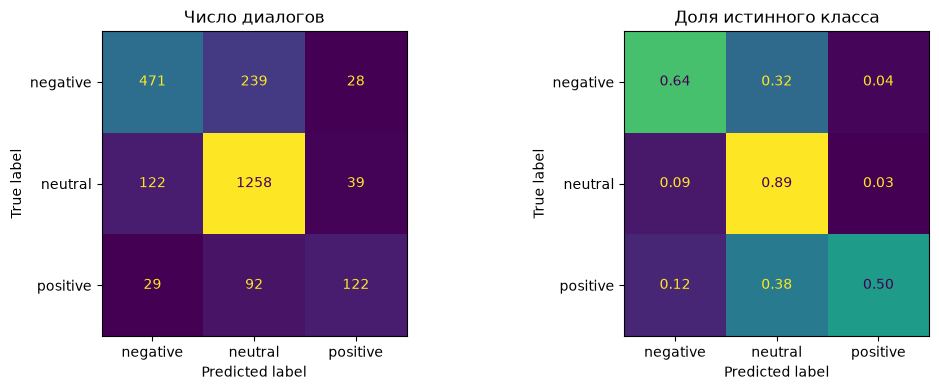

NameError: name 'test_dialogs' is not defined

In [23]:
import experiments.course_ovr as course_ovr
course_result = course_ovr.run(train_data, next_assistant=True)
course_ovr.display_result(course_result)
bundle = joblib.load(course_ovr.RESULT_DIR / 'next_assistant/final_model.joblib')
predictions = course_ovr.predict(bundle, test_dialogs)


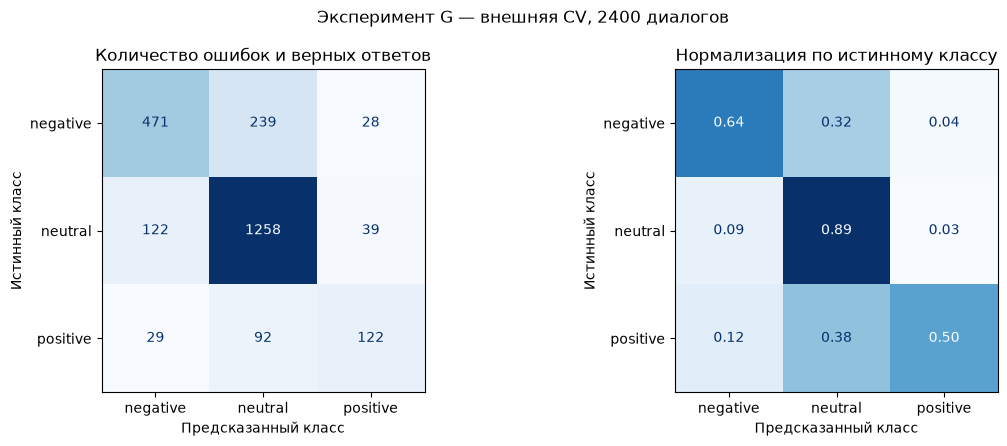

In [24]:
cm_path = Path('artifacts/course_ovr/next_assistant/results.joblib')
if cm_path.exists():
    cm_result = joblib.load(cm_path)
elif 'course_result' in globals():
    cm_result = course_result
else:
    cm_result = None
if cm_result is not None:
    cm_y_true = np.asarray(cm_result['y'])
    cm_y_pred = np.asarray(cm_result['predictions'])
    if cm_y_true.shape != cm_y_pred.shape or not len(cm_y_true):
        raise ValueError('Некорректные размеры истинных меток и предсказаний')
    cm_labels = ['negative', 'neutral', 'positive']
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, normalization, title in zip(axes, [None, 'true'], ['Количество ошибок и верных ответов', 'Нормализация по истинному классу']):
        ConfusionMatrixDisplay.from_predictions(cm_y_true, cm_y_pred, labels=cm_labels, normalize=normalization, cmap='Blues', values_format='d' if normalization is None else '.2f', colorbar=False, ax=ax)
        ax.set_title(title)
        ax.set_xlabel('Предсказанный класс')
        ax.set_ylabel('Истинный класс')
    fig.suptitle(f'Эксперимент G — внешняя CV, {len(cm_y_true)} диалогов')
    fig.tight_layout()
    plt.show()


### убираем части G

по одному блоку, чтобы понять, что помогает. ещё порог повыше к концу: поздняя ложная реакция всё перекрывает

теперь выясним, на что Гриша вообще смотрит :^


full: fold 1/5, Macro-F1=0.7113
full_position_threshold: fold 1/5, Macro-F1=0.7113
without_next: fold 1/5, Macro-F1=0.6984
without_previous: fold 1/5, Macro-F1=0.6916
without_structure: fold 1/5, Macro-F1=0.7080
shared_text: fold 1/5, Macro-F1=0.6857
full: fold 2/5, Macro-F1=0.6834
full_position_threshold: fold 2/5, Macro-F1=0.6834
without_next: fold 2/5, Macro-F1=0.6420
without_previous: fold 2/5, Macro-F1=0.6828
without_structure: fold 2/5, Macro-F1=0.6908
shared_text: fold 2/5, Macro-F1=0.6517
full: fold 3/5, Macro-F1=0.7692
full_position_threshold: fold 3/5, Macro-F1=0.7692
without_next: fold 3/5, Macro-F1=0.7054
without_previous: fold 3/5, Macro-F1=0.7493
without_structure: fold 3/5, Macro-F1=0.7467
shared_text: fold 3/5, Macro-F1=0.7372
full: fold 4/5, Macro-F1=0.6723
full_position_threshold: fold 4/5, Macro-F1=0.6743
without_next: fold 4/5, Macro-F1=0.6399
without_previous: fold 4/5, Macro-F1=0.6740
without_structure: fold 4/5, Macro-F1=0.6700
shared_text: fold 4/5, Macro-F1=0.6

,OOF_Macro_F1,Mean_CV_Macro_F1,Delta_vs_full
variant,,,
full,0.6980,0.6971,0.0000
without_next,0.6636,0.6623,-0.0344
without_previous,0.6875,0.6859,-0.0105
without_structure,0.6891,0.6877,-0.0089
shared_text,0.6818,0.6804,-0.0162
full_position_threshold,0.6983,0.6975,0.0003


Изменение Macro-F1 относительно полной модели на каждом внешнем фолде:


variant,full,full_position_threshold,shared_text,without_next,without_previous,without_structure
fold,,,,,,
1,0.0,0.000,-0.0256,-0.0129,-0.0197,-0.0033
2,0.0,0.000,-0.0317,-0.0414,-0.0005,0.0074
3,0.0,0.000,-0.0320,-0.0638,-0.0199,-0.0225
4,0.0,0.002,-0.0066,-0.0324,0.0017,-0.0023
5,0.0,0.000,0.0127,-0.0235,-0.0173,-0.0265


full
OOF Macro-F1: 0.6980; mean CV: 0.6971
              precision    recall  f1-score   support

    negative       0.76      0.64      0.69       738
     neutral       0.79      0.89      0.84      1419
    positive       0.65      0.50      0.56       243

    accuracy                           0.77      2400
   macro avg       0.73      0.68      0.70      2400
weighted avg       0.77      0.77      0.76      2400



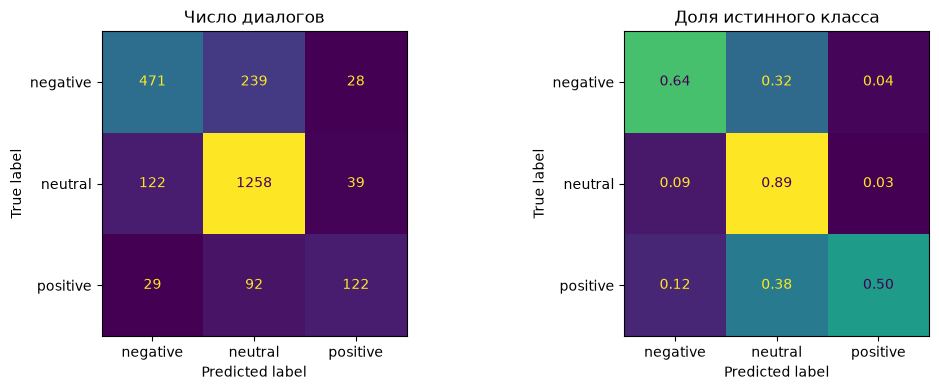

without_next
OOF Macro-F1: 0.6636; mean CV: 0.6623
              precision    recall  f1-score   support

    negative       0.71      0.61      0.66       738
     neutral       0.78      0.86      0.82      1419
    positive       0.57      0.47      0.51       243

    accuracy                           0.74      2400
   macro avg       0.69      0.65      0.66      2400
weighted avg       0.74      0.74      0.74      2400



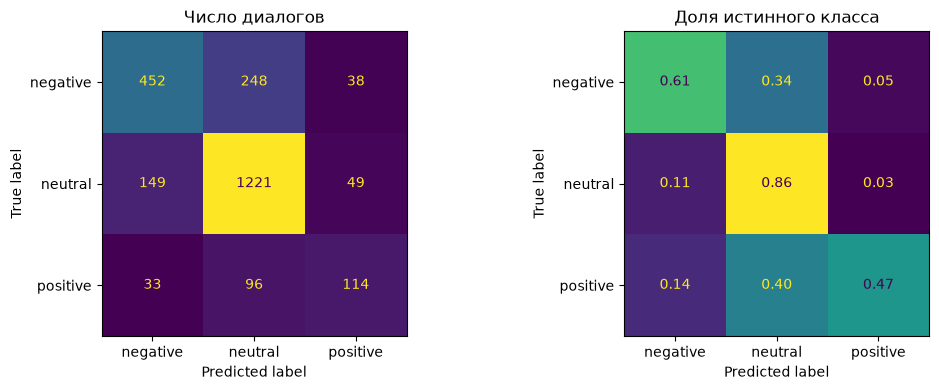

without_previous
OOF Macro-F1: 0.6875; mean CV: 0.6859
              precision    recall  f1-score   support

    negative       0.71      0.67      0.69       738
     neutral       0.80      0.84      0.82      1419
    positive       0.61      0.51      0.56       243

    accuracy                           0.76      2400
   macro avg       0.71      0.67      0.69      2400
weighted avg       0.75      0.76      0.75      2400



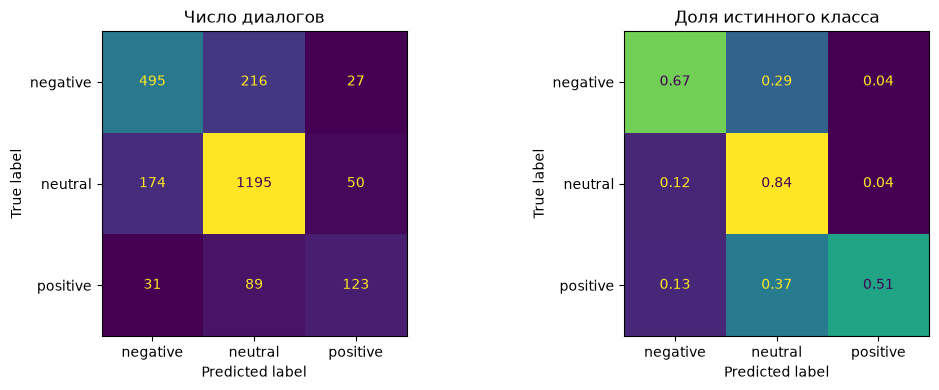

without_structure
OOF Macro-F1: 0.6891; mean CV: 0.6877
              precision    recall  f1-score   support

    negative       0.71      0.66      0.69       738
     neutral       0.80      0.85      0.82      1419
    positive       0.61      0.51      0.56       243

    accuracy                           0.76      2400
   macro avg       0.71      0.67      0.69      2400
weighted avg       0.75      0.76      0.75      2400



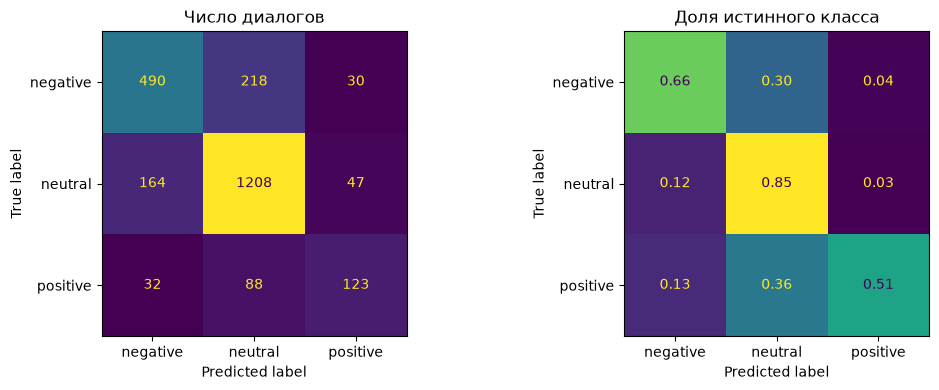

shared_text
OOF Macro-F1: 0.6818; mean CV: 0.6804
              precision    recall  f1-score   support

    negative       0.70      0.68      0.69       738
     neutral       0.80      0.85      0.82      1419
    positive       0.64      0.46      0.54       243

    accuracy                           0.76      2400
   macro avg       0.71      0.66      0.68      2400
weighted avg       0.75      0.76      0.75      2400



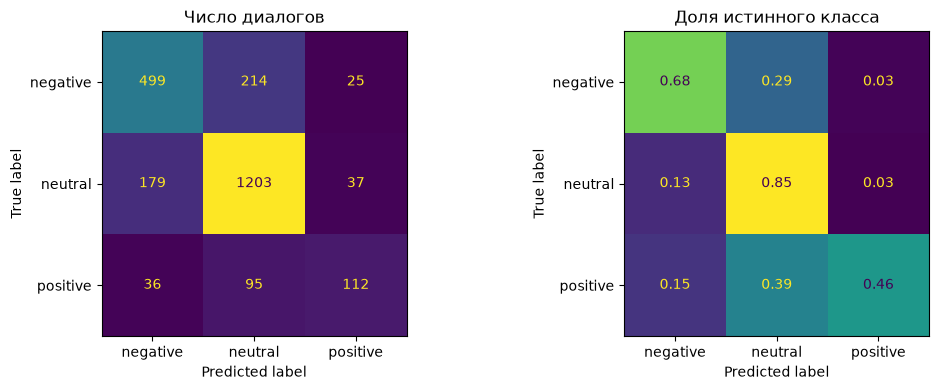

full_position_threshold
OOF Macro-F1: 0.6983; mean CV: 0.6975
              precision    recall  f1-score   support

    negative       0.75      0.65      0.70       738
     neutral       0.79      0.88      0.84      1419
    positive       0.64      0.50      0.56       243

    accuracy                           0.77      2400
   macro avg       0.73      0.68      0.70      2400
weighted avg       0.77      0.77      0.77      2400



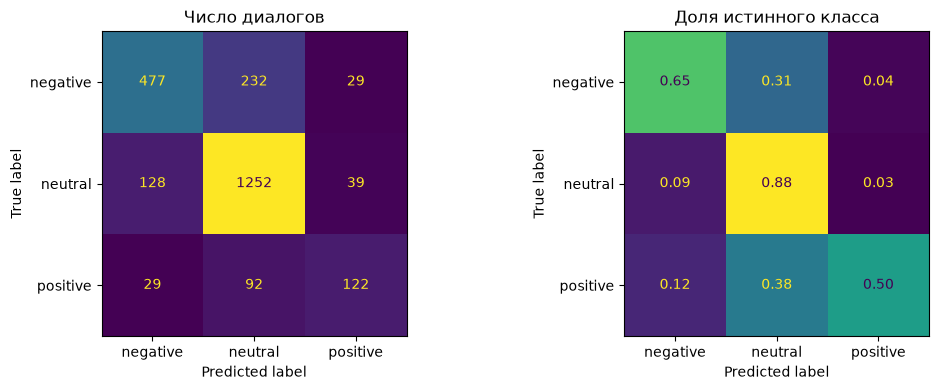

In [27]:
import experiments.course_ablation as course_ablation
ablation_result = course_ablation.run(train_data)
display(ablation_result['table'].round(4))
display(ablation_result['paired_deltas'].round(4))
for name, predictions in ablation_result['predictions'].items():
    print(name)
    course_ovr.display_result(dict(y=ablation_result['y'], predictions=predictions, macro_f1=ablation_result['table'].loc[name, 'OOF_Macro_F1'], mean_cv_macro_f1=ablation_result['table'].loc[name, 'Mean_CV_Macro_F1']))


### добавим svd

100-300 компонент рядом с исходным tf-idf. контроль без svd

  inner dimension=None, Macro-F1=0.6759
  inner dimension=100, Macro-F1=0.6751
  inner dimension=200, Macro-F1=0.6726
  inner dimension=300, Macro-F1=0.6716
user_tfidf: fold 1/5, dim=None, Macro-F1=0.7083
user_tfidf_plus_svd: fold 1/5, dim=100, Macro-F1=0.7053
  inner dimension=None, Macro-F1=0.6593
  inner dimension=100, Macro-F1=0.6644
  inner dimension=200, Macro-F1=0.6643
  inner dimension=300, Macro-F1=0.6639
user_tfidf: fold 2/5, dim=None, Macro-F1=0.6421
user_tfidf_plus_svd: fold 2/5, dim=100, Macro-F1=0.6416
  inner dimension=None, Macro-F1=0.6634
  inner dimension=100, Macro-F1=0.6679
  inner dimension=200, Macro-F1=0.6638
  inner dimension=300, Macro-F1=0.6668
user_tfidf: fold 3/5, dim=None, Macro-F1=0.6963
user_tfidf_plus_svd: fold 3/5, dim=100, Macro-F1=0.7036
  inner dimension=None, Macro-F1=0.6857
  inner dimension=100, Macro-F1=0.6846
  inner dimension=200, Macro-F1=0.6838
  inner dimension=300, Macro-F1=0.6825
user_tfidf: fold 4/5, dim=None, Macro-F1=0.6448
user_tfidf_p

,OOF_Macro_F1,Mean_CV_Macro_F1,Delta_vs_user_tfidf
variant,,,
user_tfidf,0.6598,0.6594,0.0000
user_tfidf_plus_svd,0.6610,0.6609,0.0013


,variant,fold,dimension,positive,negative,thresholds,alphas,inner_macro_f1
0,user_tfidf,1,NaN,"(0.1, balanced)","(0.1, balanced)","(0.5, 0.5)","(0.0, 0.0)",0.675944
1,user_tfidf_plus_svd,1,100.0,"(0.1, balanced)","(0.1, balanced)","(0.5, 0.5)","(0.0, 0.0)",0.675117
2,user_tfidf,2,NaN,"(0.1, balanced)","(0.1, balanced)","(0.5, 0.5)","(0.0, 0.0)",0.659270
3,user_tfidf_plus_svd,2,100.0,"(0.1, balanced)","(0.1, None)","(0.5, -0.5)","(0.0, 0.0)",0.664377
4,user_tfidf,3,NaN,"(0.1, balanced)","(0.1, None)","(0.5, -0.5)","(0.0, 0.0)",0.663409
5,user_tfidf_plus_svd,3,100.0,"(0.1, balanced)","(0.1, None)","(0.5, -0.5)","(0.0, 0.0)",0.667889
6,user_tfidf,4,NaN,"(0.3, balanced)","(0.1, balanced)","(0.5, 0.5)","(0.0, 0.0)",0.685703
7,user_tfidf_plus_svd,4,100.0,"(0.3, balanced)","(0.1, None)","(0.5, -0.5)","(0.0, 0.0)",0.684630
8,user_tfidf,5,NaN,"(1.0, None)","(0.1, None)","(-0.5, -0.5)","(0.0, 0.0)",0.687437
9,user_tfidf_plus_svd,5,100.0,"(1.0, None)","(0.1, None)","(-0.5, -0.5)","(0.0, 0.0)",0.690512


user_tfidf
OOF Macro-F1: 0.6598; mean CV: 0.6594
              precision    recall  f1-score   support

    negative       0.68      0.61      0.64       738
     neutral       0.77      0.85      0.81      1419
    positive       0.63      0.45      0.52       243

    accuracy                           0.74      2400
   macro avg       0.69      0.64      0.66      2400
weighted avg       0.73      0.74      0.73      2400



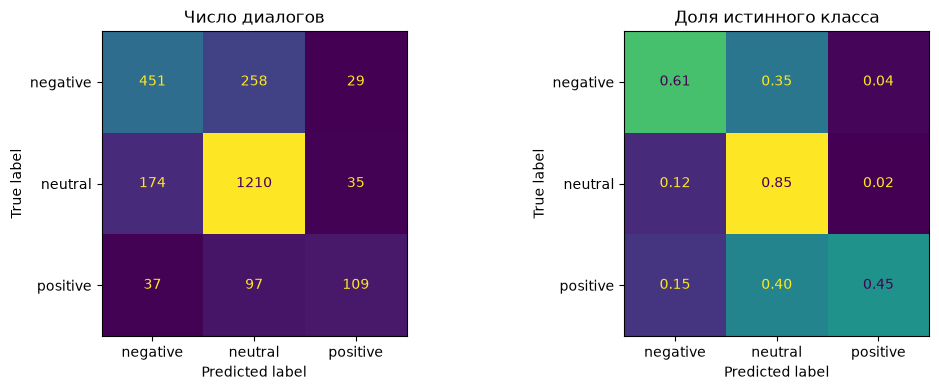

user_tfidf_plus_svd
OOF Macro-F1: 0.6610; mean CV: 0.6609
              precision    recall  f1-score   support

    negative       0.68      0.62      0.65       738
     neutral       0.78      0.85      0.81      1419
    positive       0.61      0.46      0.52       243

    accuracy                           0.74      2400
   macro avg       0.69      0.64      0.66      2400
weighted avg       0.73      0.74      0.73      2400



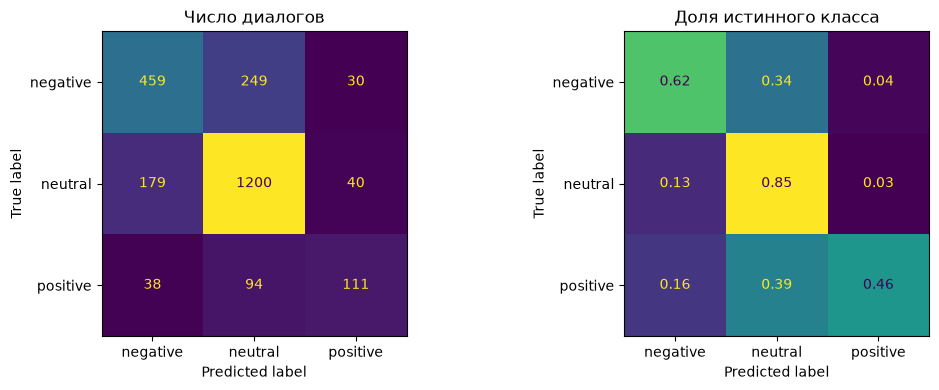

  inner dimension=None, Macro-F1=0.6680
  inner dimension=100, Macro-F1=0.6695
  inner dimension=200, Macro-F1=0.6711
  inner dimension=300, Macro-F1=0.6699


NameError: name 'test_dialogs' is not defined

In [30]:
import experiments.course_ovr as course_ovr
import experiments.course_svd as course_svd
SVD_DIMENSIONS = [100, 200, 300]
svd_result = course_svd.run(train_data, dimensions=SVD_DIMENSIONS)
display(svd_result['table'].round(4))
display(pd.DataFrame(svd_result['choices']))
for name, pred in svd_result['predictions'].items():
    print(name)
    course_ovr.display_result(dict(y=svd_result['y'], predictions=pred, macro_f1=svd_result['table'].loc[name, 'OOF_Macro_F1'], mean_cv_macro_f1=svd_result['table'].loc[name, 'Mean_CV_Macro_F1']))
svd_bundle = course_svd.train_final(train_data, dimensions=SVD_DIMENSIONS)
joblib.dump(svd_bundle, course_svd.RESULT_DIR / 'final_model.joblib')
svd_predictions = course_svd.predict(svd_bundle, test_dialogs)


### сочетания сигналов

исправление + извинение, благодарность и т. п. сначала сами признаки, потом их произведения

In [32]:
import experiments.course_ovr as course_ovr
import experiments.course_interactions as course_interactions
interaction_result = course_interactions.run(train_data)
display(interaction_result['table'].round(4))
display(interaction_result['paired'].round(4))
for name, pred in interaction_result['predictions'].items():
    print(name)
    course_ovr.display_result(dict(y=interaction_result['y'], predictions=pred, macro_f1=interaction_result['table'].loc[name, 'OOF_Macro_F1'], mean_cv_macro_f1=interaction_result['table'].loc[name, 'Mean_CV_Macro_F1']))
signals_bundle = course_interactions.train_final(train_data, variant='G_signals')
joblib.dump(signals_bundle, course_interactions.RESULT_DIR / 'final_model.joblib')


G_control: fold 1/5, Macro-F1=0.7113
G_signals: fold 1/5, Macro-F1=0.7354
G_interactions: fold 1/5, Macro-F1=0.7046
G_control: fold 2/5, Macro-F1=0.6834
G_signals: fold 2/5, Macro-F1=0.6792


KeyboardInterrupt: 

### нейтральность целого диалога

lr по оценкам всех реплик. знак пока оставим G

In [ ]:
import experiments.course_gate as course_gate
sequence_result = course_gate.run(train_data, n_jobs=2)
display(sequence_result['table'].round(4))
display(sequence_result['fold_scores'].pivot(index='fold', columns='variant', values='macro_f1').round(4))
for name, pred in sequence_result['predictions'].items():
    print(name)
    course_ovr.display_result(dict(y=sequence_result['y'], predictions=pred, macro_f1=sequence_result['table'].loc[name, 'OOF_Macro_F1'], mean_cv_macro_f1=sequence_result['table'].loc[name, 'Mean_CV_Macro_F1']))


### только non-neutral

первая lr на репликах, вторая собирает их оценки. знак здесь не определяем

In [ ]:
import experiments.binary_feedback as feedback_model
feedback_result = feedback_model.run(train_data)
feedback_model.display_result(feedback_result)


### где ошибается G

пропуск нужной реплики / ложная после неё / неверный знак / ложная в neutral-диалоге

In [ ]:
import experiments.reaction_error_analysis as reaction_error_analysis
ERROR_CHECKPOINT_DIR = Path('artifacts/course_interactions/08d2a210920f3f20')
error_analysis = reaction_error_analysis.reconstruct(train_data, ERROR_CHECKPOINT_DIR)
reaction_error_analysis.display_result(error_analysis)


### оценки svm

посмотрим, где относительно порога пропуски и ложные реакции. это train, не oof

Совместимость: модель sklearn 1.6.1, текущая версия 1.9.1 — адаптирована только служебная запись отброшенных колонок.
ТОЛЬКО ДИАГНОСТИКА НА TRAIN: финальная модель обучалась на этих диалогах.
Это не OOF-распределения и не воспроизведение ошибок прежней CV.
Диалогов: 2400 реплик: 13685 определяющих с неверным знаком (вне трёх групп): 0
Группа 3 требует правильного знака. Группа 2 включает все neutral-реплики, не только поздние.


,group,score,n,mean,q10,median,q90
0,Пропущенные определяющие,positive_score,137,-2.4388,-3.2803,-2.3987,-1.7508
1,Пропущенные определяющие,negative_score,137,0.2119,-0.0622,0.2781,0.4606
2,Пропущенные определяющие,nonneutral_margin,137,-0.2620,-0.5401,-0.2147,-0.0394
3,Ложные реакции на neutral-репликах,positive_score,165,-2.9348,-3.8179,-2.9094,-2.0275
4,Ложные реакции на neutral-репликах,negative_score,165,0.8646,0.5457,0.7690,1.2946
5,Ложные реакции на neutral-репликах,nonneutral_margin,165,0.3646,0.0457,0.2690,0.7946
6,Верно распознанные определяющие,positive_score,844,-1.4816,-3.5906,-2.4548,1.5435
7,Верно распознанные определяющие,negative_score,844,0.6208,-1.3366,0.9674,1.9261
8,Верно распознанные определяющие,nonneutral_margin,844,1.1224,0.2259,0.8318,1.9855


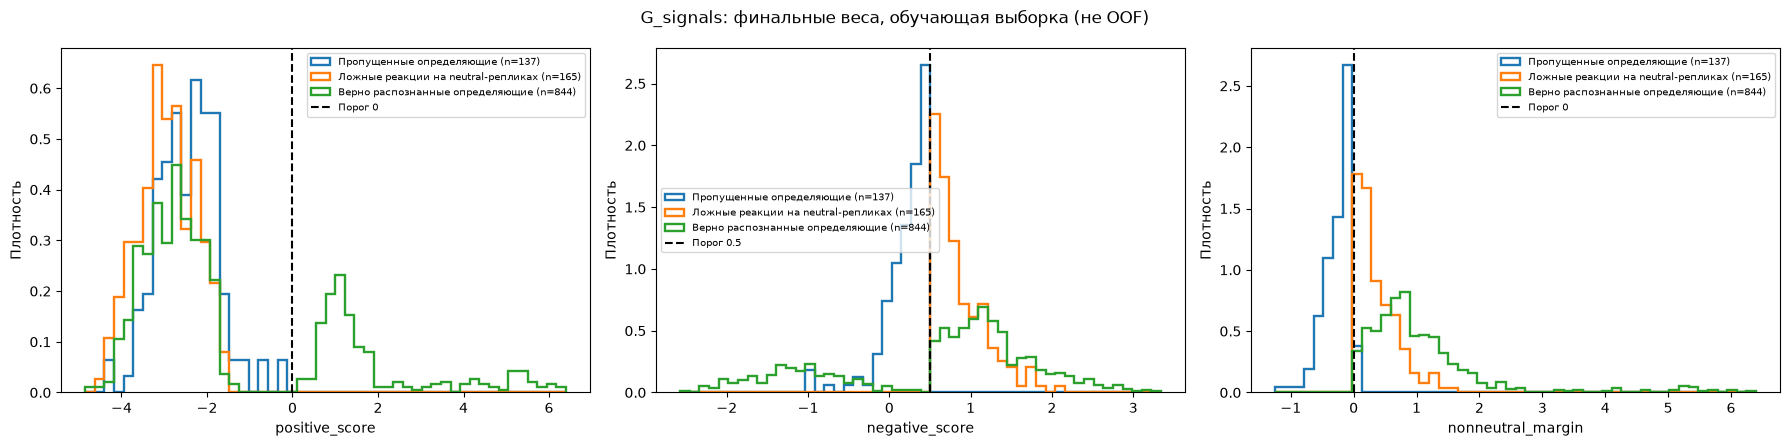

Важно: max(score_positive−t_positive, score_negative−t_negative) < 0 у пропусков
и >= 0 у срабатываний по определению. Разделение этих групп этим margin само по себе
не доказывает, что новый порог улучшит качество. OOF-оценок реплик в архиве нет.


In [1]:
from experiments.course_ovr import interactions
SCORE_MODEL = Path('artifacts/course_interactions/final_model.joblib')
SCORE_DATA = Path('data/hw1_train.jsonl')
SCORE_OUTPUT = Path('artifacts/svc_score_distributions')

class _UnusedLegacyRemainder:
    pass
_had_legacy = hasattr(_ct, '_RemainderColsList')
_legacy_original = getattr(_ct, '_RemainderColsList', None)
try:
    if not _had_legacy:
        _ct._RemainderColsList = _UnusedLegacyRemainder
    with warnings.catch_warnings(record=True) as load_warnings:
        warnings.simplefilter('always', InconsistentVersionWarning)
        score_bundle = joblib.load(SCORE_MODEL)
finally:
    if not _had_legacy:
        delattr(_ct, '_RemainderColsList')
if score_bundle.get('variant') != 'G_signals':
    raise ValueError(f"Ожидалась G_signals, сохранена {score_bundle.get('variant')}")
score_base = dict(score_bundle['encoder'].transformer_list)['G']
for name, transformer, columns in score_base.transformers_:
    if isinstance(columns, _UnusedLegacyRemainder) and (name != 'remainder' or transformer != 'drop'):
        raise RuntimeError('Несовместимый рабочий трансформер: используйте исходную версию sklearn')
score_base.transformers_ = [(name, transformer, columns) for name, transformer, columns in score_base.transformers_ if not (name == 'remainder' and transformer == 'drop')]
with SCORE_DATA.open(encoding='utf-8') as stream:
    records = [json.loads(line) for line in stream if line.strip()]
by_id = {row['dialog_id']: row for row in records if row.get('labels')}
score_ids = score_bundle['train_dialog_ids']
if len(set(score_ids)) != len(score_ids) or any((key not in by_id for key in score_ids)):
    raise ValueError('Не удалось сопоставить train_dialog_ids модели с данными')
score_dialogs = pd.DataFrame([by_id[key] for key in score_ids])
score_dialogs['reaction'] = score_dialogs.labels.map(lambda labels: labels['reaction'])
score_pairs = interactions(score_dialogs[['dialog_id', 'turns']], training=False)
with threadpool_limits(limits=1):
    score_x = score_bundle['encoder'].transform(score_pairs)
    if score_x.shape[1] != score_bundle['models']['positive'][0].coef_.shape[1]:
        raise ValueError('Число признаков отличается от сохранённых весов')
    score_values = {label: model.decision_function(score_x) / scale for label, (model, scale) in score_bundle['models'].items()}
score_tp, score_tn = score_bundle['choice']['thresholds']
score_ep = score_values['positive'] - score_tp
score_en = score_values['negative'] - score_tn
score_margin = np.maximum(score_ep, score_en)
score_pred = np.where(score_margin >= 0, np.where(score_ep > score_en, 'positive', 'negative'), 'neutral')
if not all((np.isfinite(values).all() for values in score_values.values())):
    raise ValueError('Нечисловые оценки SVC')
score_true = []
score_decisive = np.zeros(len(score_pairs), dtype=bool)
score_offset = 0
for row in score_dialogs.itertuples(index=False):
    reactions = [turn['reaction'] for turn in row.labels['user_turns'][1:]]
    if not set(reactions) <= {'negative', 'neutral', 'positive'}:
        raise ValueError('Неразмеченная реакция среди кандидатов')
    nonneutral = [i for i, value in enumerate(reactions) if value != 'neutral']
    if nonneutral:
        score_decisive[score_offset + nonneutral[-1]] = True
    expected = reactions[nonneutral[-1]] if nonneutral else 'neutral'
    if expected != row.reaction:
        raise ValueError('Правило последней ненейтральной реакции не совпало с target')
    score_true.extend(reactions)
    score_offset += len(reactions)
score_true = np.asarray(score_true)
if len(score_true) != len(score_pred):
    raise ValueError('Не совпало число пользовательских реакций')
score_masks = {'Пропущенные определяющие': score_decisive & (score_pred == 'neutral'), 'Ложные реакции на neutral-репликах': (score_true == 'neutral') & (score_pred != 'neutral'), 'Верно распознанные определяющие': score_decisive & (score_pred == score_true)}
score_wrong_sign = score_decisive & (score_pred != 'neutral') & (score_pred != score_true)
print('Диалогов:', len(score_dialogs), 'реплик:', len(score_pairs), 'определяющих с неверным знаком (вне трёх групп):', int(score_wrong_sign.sum()))
score_table = pd.DataFrame({'dialog_id': score_dialogs.dialog_id.to_numpy()[score_pairs.dialog_pos.to_numpy()], 'user_number': score_pairs.groupby('dialog_pos').cumcount().to_numpy() + 2, 'truth': score_true, 'prediction': score_pred, 'decisive': score_decisive, 'positive_score': score_values['positive'], 'negative_score': score_values['negative'], 'nonneutral_margin': score_margin, 'group': np.select(list(score_masks.values()), list(score_masks), default='other')})
score_statistics = []
for group, mask in score_masks.items():
    for feature in ['positive_score', 'negative_score', 'nonneutral_margin']:
        values = score_table.loc[mask, feature].to_numpy()
        if len(values):
            score_statistics.append(dict(group=group, score=feature, n=len(values), mean=values.mean(), q10=np.quantile(values, 0.1), median=np.median(values), q90=np.quantile(values, 0.9)))
display(pd.DataFrame(score_statistics).round(4))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, feature, threshold in zip(axes, ['positive_score', 'negative_score', 'nonneutral_margin'], [score_tp, score_tn, 0.0]):
    selected = np.logical_or.reduce(list(score_masks.values()))
    values = score_table.loc[selected, feature].to_numpy()
    bins = np.histogram_bin_edges(values, bins=50) if len(values) else 50
    for group, mask in score_masks.items():
        values = score_table.loc[mask, feature].to_numpy()
        if len(values):
            ax.hist(values, bins=bins, density=True, histtype='step', linewidth=1.7, label=f'{group} (n={len(values)})')
    ax.axvline(threshold, color='black', linestyle='--', label=f'Порог {threshold:g}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Плотность')
    ax.legend(fontsize=7)
fig.suptitle('G_signals: финальные веса, обучающая выборка (не OOF)')
fig.tight_layout()
SCORE_OUTPUT.mkdir(parents=True, exist_ok=True)
fig.savefig(SCORE_OUTPUT / 'train_score_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
score_table.to_csv(SCORE_OUTPUT / 'train_turn_scores.csv', index=False)
pd.DataFrame(score_statistics).to_csv(SCORE_OUTPUT / 'train_score_statistics.csv', index=False)


### сами тексты ошибок

до 30 из каждой группы, с контекстом. тоже train

In [ ]:
EXAMPLE_COUNT = 30
EXAMPLE_SEED = 42
EXAMPLE_SCORES = Path('artifacts/svc_score_distributions/train_turn_scores.csv')
EXAMPLE_DATA = Path('data/hw1_train.jsonl')
EXAMPLE_OUTPUT = Path('artifacts/svc_score_distributions/examples')
if not EXAMPLE_SCORES.exists():
    raise FileNotFoundError('Сначала выполните предыдущую ячейку распределений SVC: нужны train_turn_scores.csv')
examples_scores = pd.read_csv(EXAMPLE_SCORES, dtype={'dialog_id': str})
with EXAMPLE_DATA.open(encoding='utf-8') as stream:
    examples_records = {row['dialog_id']: row for row in (json.loads(line) for line in stream if line.strip())}
examples_rows = []
for scored in examples_scores.to_dict('records'):
    record = examples_records[scored['dialog_id']]
    annotations = record['labels']['user_turns']
    ordinal = int(scored['user_number']) - 1
    true = annotations[ordinal]['reaction']
    if true != scored['truth']:
        raise ValueError('Разметка не совпала с сохранёнными оценками')
    nonneutral = [i for i, a in enumerate(annotations) if a.get('reaction') in ['positive', 'negative']]
    wholly_neutral = bool(annotations[1:]) and all((a.get('reaction') == 'neutral' for a in annotations[1:]))
    if nonneutral and ordinal == nonneutral[-1] and (scored['prediction'] == 'neutral'):
        group = 'missed_decisive'
    elif wholly_neutral and true == 'neutral' and (scored['prediction'] in ['positive', 'negative']):
        group = 'false_reaction_in_neutral_dialogue'
    else:
        continue
    users = [i for i, t in enumerate(record['turns']) if t['role'] == 'user']
    position = users[ordinal]
    turns = record['turns']
    previous = turns[position - 1] if position else {}
    following = turns[position + 1] if position + 1 < len(turns) else {}
    examples_rows.append(dict(group=group, dialog_id=record['dialog_id'], user_number=ordinal + 1, user_text=turns[position]['text'], previous_assistant=previous.get('text', '') if previous.get('role') == 'assistant' else '', next_assistant=following.get('text', '') if following.get('role') == 'assistant' else '', true_reaction=true, positive_score=scored['positive_score'], negative_score=scored['negative_score'], predicted_reaction=scored['prediction'], nonneutral_margin=scored['nonneutral_margin']))
examples_columns = ['group', 'dialog_id', 'user_number', 'user_text', 'previous_assistant', 'next_assistant', 'true_reaction', 'positive_score', 'negative_score', 'predicted_reaction', 'nonneutral_margin']
examples_candidates = pd.DataFrame(examples_rows, columns=examples_columns)
EXAMPLE_OUTPUT.mkdir(parents=True, exist_ok=True)
examples_selected = {}
examples_html = ['<h2>Тексты ошибок G_signals</h2><p>Финальная модель на train, не OOF. Случайная выборка без повторов реплик, seed=42. Несколько реплик могут относиться к одному диалогу.</p>']
for group, title in [('missed_decisive', 'Пропущенные определяющие реплики'), ('false_reaction_in_neutral_dialogue', 'Ложные реакции в полностью нейтральных диалогах')]:
    candidates = examples_candidates[examples_candidates.group == group]
    selected = candidates.sample(n=min(EXAMPLE_COUNT, len(candidates)), random_state=EXAMPLE_SEED).reset_index(drop=True)
    examples_selected[group] = selected
    selected.to_csv(EXAMPLE_OUTPUT / f'{group}.csv', index=False)
    selected.to_json(EXAMPLE_OUTPUT / f'{group}.jsonl', orient='records', lines=True, force_ascii=False)
    examples_html.append(f'<h3>{html.escape(title)} — {len(selected)} примеров</h3>')
    for number, row in enumerate(selected.to_dict('records'), 1):
        caption = f"{number}. {row['dialog_id']} / User {row['user_number']} — true={row['true_reaction']}, pred={row['predicted_reaction']}; positive={row['positive_score']:.4f}, negative={row['negative_score']:.4f}"
        examples_html.append('<details><summary>' + html.escape(caption) + '</summary>')
        for field in ['previous_assistant', 'user_text', 'next_assistant']:
            examples_html.append('<h4>' + field + '</h4><pre style="white-space:pre-wrap;overflow-wrap:anywhere">' + html.escape(row[field]) + '</pre>')
        examples_html.append('</details>')
examples_html = '\n'.join(examples_html)
(EXAMPLE_OUTPUT / 'examples.html').write_text('<meta charset="utf-8">' + examples_html, encoding='utf-8')
display(HTML(examples_html))


### техническая ошибка или претензия к ответу

посмотрим на ошибки, исправления и извинения. пока только разбор train

In [2]:
import experiments.problem_source_features as problem_source_features
problem_scores = pd.read_csv(
    'artifacts/svc_score_distributions/train_turn_scores.csv',
    dtype={'dialog_id': str},
)
with Path('data/hw1_train.jsonl').open(encoding='utf-8') as stream:
    problem_records = {r['dialog_id']: r for r in (json.loads(line) for line in stream if line.strip())}
problem_context = []
for row in problem_scores.to_dict('records'):
    record = problem_records[row['dialog_id']]
    users = [i for i, t in enumerate(record['turns']) if t['role'] == 'user']
    ordinal = int(row['user_number']) - 1
    pos = users[ordinal]
    if record['labels']['user_turns'][ordinal]['reaction'] != row['truth']:
        raise ValueError('Не совпала сохранённая разметка')
    following = record['turns'][pos + 1] if pos + 1 < len(record['turns']) else {}
    problem_context.append({'user': record['turns'][pos]['text'], 'following': following['text'][:600] if following.get('role') == 'assistant' else ''})
problem_context = pd.DataFrame(problem_context)
problem_transformer = problem_source_features.ProblemSourceFeatures()
problem_flags = pd.DataFrame(
    problem_transformer.transform(problem_context).toarray().astype(bool),
    columns=problem_transformer.get_feature_names_out(),
)
problem_audit = pd.concat([problem_scores.reset_index(drop=True), problem_flags], axis=1)
problem_audit['wrong'] = problem_audit.truth != problem_audit.prediction
problem_audit['false_nonneutral'] = (problem_audit.truth == 'neutral') & (problem_audit.prediction != 'neutral')
problem_audit['missed_nonneutral'] = (problem_audit.truth != 'neutral') & (problem_audit.prediction == 'neutral')
problem_rows = []
for flag in ['ALL'] + list(problem_flags.columns):
    for present in [True] if flag == 'ALL' else [True, False]:
        subset = problem_audit if flag == 'ALL' else problem_audit[problem_audit[flag] == present]
        n = len(subset)
        neutral = subset.truth.eq('neutral')
        nonneutral = ~neutral
        problem_rows.append(dict(feature=flag, present=present, n=n, neutral_share=neutral.mean() if n else np.nan, negative_share=subset.truth.eq('negative').mean() if n else np.nan, positive_share=subset.truth.eq('positive').mean() if n else np.nan, wrong_count=int(subset.wrong.sum()), error_rate=subset.wrong.mean() if n else np.nan, false_nonneutral_count=int(subset.false_nonneutral.sum()), false_nonneutral_rate=subset.loc[neutral, 'false_nonneutral'].mean() if neutral.any() else np.nan, missed_nonneutral_count=int(subset.missed_nonneutral.sum()), missed_nonneutral_rate=subset.loc[nonneutral, 'missed_nonneutral'].mean() if nonneutral.any() else np.nan))
problem_summary = pd.DataFrame(problem_rows)
display(problem_summary.round(4))
problem_joint = problem_audit.groupby(['technical_error', 'assistant_apology'], dropna=False).agg(
    n=('truth', 'size'),
    neutral_share=('truth', lambda x: x.eq('neutral').mean()),
    false_nonneutral_count=('false_nonneutral', 'sum'),
    error_rate=('wrong', 'mean'),
)
display(problem_joint.round(4))
problem_output = Path('artifacts/svc_score_distributions/problem_source')
problem_output.mkdir(parents=True, exist_ok=True)
problem_audit.to_csv(problem_output / 'turn_flags.csv', index=False)
problem_summary.to_csv(problem_output / 'summary.csv', index=False)
problem_joint.to_csv(problem_output / 'technical_apology_combinations.csv')
problem_selected = problem_audit.technical_and_apology & problem_audit.false_nonneutral
problem_examples = pd.concat(
    [problem_audit.loc[problem_selected].reset_index(drop=True), problem_context.loc[problem_selected].reset_index(drop=True)],
    axis=1,
)
problem_examples.to_json(problem_output / 'technical_apology_false_positives.jsonl', orient='records', lines=True, force_ascii=False)


Аудит всех сохранённых train-реплик, не OOF. Regex-флаги — поверхностные сигналы, а не достоверное определение причины.


,feature,present,n,neutral_share,negative_share,positive_share,wrong_count,error_rate,false_nonneutral_count,false_nonneutral_rate,missed_nonneutral_count,missed_nonneutral_rate
0,ALL,True,13685,0.8269,0.1413,0.0318,441,0.0322,165,0.0146,276,0.1165
1,technical_error,True,253,0.3162,0.6759,0.0079,20,0.0791,19,0.2375,1,0.0058
2,technical_error,False,13432,0.8365,0.1313,0.0322,421,0.0313,146,0.0130,275,0.1252
3,assistant_correction,True,48,0.3333,0.6458,0.0208,2,0.0417,2,0.1250,0,0.0000
4,assistant_correction,False,13637,0.8286,0.1395,0.0318,439,0.0322,163,0.0144,276,0.1181
5,requirement_mismatch,True,150,0.7000,0.2867,0.0133,12,0.0800,6,0.0571,6,0.1333
6,requirement_mismatch,False,13535,0.8283,0.1397,0.0320,429,0.0317,159,0.0142,270,0.1162
7,explicit_dissatisfaction,True,20,0.7500,0.2000,0.0500,1,0.0500,0,0.0000,1,0.2000
8,explicit_dissatisfaction,False,13665,0.8270,0.1412,0.0318,440,0.0322,165,0.0146,275,0.1163
9,assistant_apology,True,1587,0.3459,0.6434,0.0107,131,0.0825,120,0.2186,11,0.0106


n  neutral_share  \
technical_error assistant_apology                         
False           False              11927         0.8970   
                True                1505         0.3575   
True            False                171         0.4035   
                True                  82         0.1341   

                                   false_nonneutral_count  error_rate  
technical_error assistant_apology                                      
False           False                                  35      0.0251  
                True                                  111      0.0811  
True            False                                  10      0.0643  
                True                                    9      0.1098

Сохранено: /home/nika/ML_labs/artifacts/svc_score_distributions/problem_source
Не считаем technical_error гарантированным neutral и не меняем предсказания G по этим правилам.


### веса по извинениям

может, svm слишком на них полагается. усилим neutral с извинением и non-neutral без него

Train: 2400 диалогов; групп: 2390
Параллельных SVM: 2 Архив: /home/nika/ML_labs/colab/experiment_M_colab.zip
Отложенный тест не загружается. Результаты: /home/nika/ML_labs/artifacts/course_sample_weight
G_signals fold 1/5: Macro-F1=0.7354, weights=(1.0, 1.0)
G_weighted fold 1/5: Macro-F1=0.7137, weights=(2.0, 1.0)
G_signals fold 2/5: Macro-F1=0.6792, weights=(1.0, 1.0)
G_weighted fold 2/5: Macro-F1=0.6862, weights=(2.0, 1.0)
G_signals fold 3/5: Macro-F1=0.7786, weights=(1.0, 1.0)
G_weighted fold 3/5: Macro-F1=0.7767, weights=(2.0, 1.0)
G_signals fold 4/5: Macro-F1=0.7077, weights=(1.0, 1.0)
G_weighted fold 4/5: Macro-F1=0.7077, weights=(1.0, 1.0)
G_signals fold 5/5: Macro-F1=0.6378, weights=(1.0, 1.0)
G_weighted fold 5/5: Macro-F1=0.6668, weights=(2.0, 1.0)
Время: 11.6 мин


,OOF_Macro_F1,Mean_CV_Macro_F1,Delta_vs_G
variant,,,
G_signals,0.7075,0.7077,0.0000
G_weighted,0.7103,0.7102,0.0028


,variant,fold,policy,positive,negative,thresholds,alphas,inner_macro_f1
0,G_signals,1,"(1.0, 1.0)","(0.3, None)","(0.1, balanced)","(-0.5, 0.5)","(0.0, 0.0)",0.704908
1,G_weighted,1,"(2.0, 1.0)","(1.0, None)","(0.1, None)","(-0.5, -0.5)","(0.0, 0.0)",0.707346
2,G_signals,2,"(1.0, 1.0)","(1.0, None)","(0.3, None)","(-0.5, 0.0)","(0.0, 0.0)",0.705275
3,G_weighted,2,"(2.0, 1.0)","(1.0, None)","(0.1, None)","(-0.5, -0.5)","(0.0, 0.0)",0.706867
4,G_signals,3,"(1.0, 1.0)","(1.0, None)","(0.1, balanced)","(-0.5, 0.5)","(0.0, 0.0)",0.707512
5,G_weighted,3,"(2.0, 1.0)","(1.0, balanced)","(0.1, None)","(0.0, -0.5)","(0.0, 0.0)",0.708892
6,G_signals,4,"(1.0, 1.0)","(0.1, balanced)","(0.1, None)","(0.5, -0.5)","(0.0, 0.0)",0.726225
7,G_weighted,4,"(1.0, 1.0)","(0.1, balanced)","(0.1, None)","(0.5, -0.5)","(0.0, 0.0)",0.726225
8,G_signals,5,"(1.0, 1.0)","(1.0, None)","(0.3, balanced)","(-0.5, 0.0)","(0.0, 0.0)",0.719704
9,G_weighted,5,"(2.0, 1.0)","(1.0, None)","(0.1, None)","(-0.5, -0.5)","(0.0, 0.0)",0.722163


variant,G_signals,G_weighted,weighted_minus_control
fold,,,
1,0.7354,0.7137,-0.0217
2,0.6792,0.6862,0.0070
3,0.7786,0.7767,-0.0019
4,0.7077,0.7077,0.0000
5,0.6378,0.6668,0.0290


G_signals
OOF Macro-F1: 0.7075; mean CV: 0.7077
              precision    recall  f1-score   support

    negative       0.72      0.70      0.71       738
     neutral       0.80      0.85      0.83      1419
    positive       0.70      0.50      0.58       243

    accuracy                           0.77      2400
   macro avg       0.74      0.69      0.71      2400
weighted avg       0.77      0.77      0.77      2400



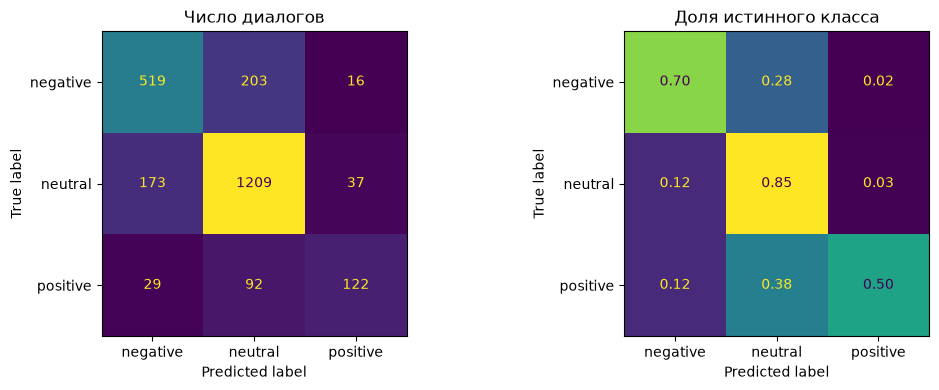

G_weighted
OOF Macro-F1: 0.7103; mean CV: 0.7102
              precision    recall  f1-score   support

    negative       0.73      0.71      0.72       738
     neutral       0.81      0.85      0.83      1419
    positive       0.67      0.52      0.58       243

    accuracy                           0.77      2400
   macro avg       0.73      0.69      0.71      2400
weighted avg       0.77      0.77      0.77      2400



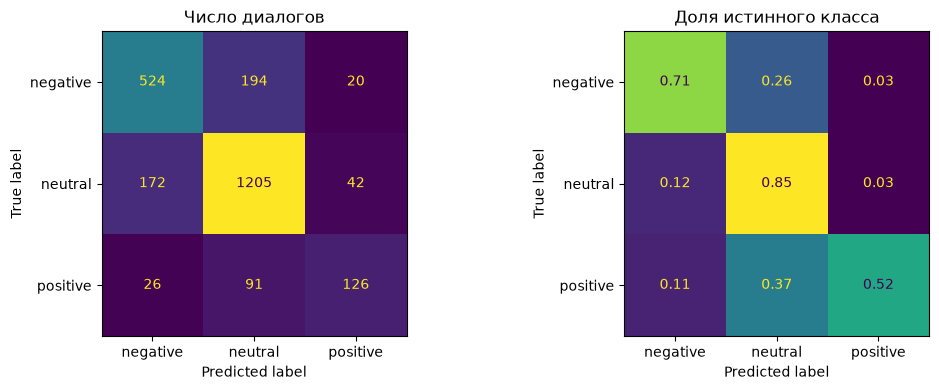

In [5]:
import experiments.course_sample_weight as weight_model
M_N_JOBS = min(2, joblib.cpu_count())
weight_result = weight_model.run(train_data, n_jobs=M_N_JOBS)
weight_model.display_result(weight_result)


### веса по важности реплики

Decision_2x: решающая реакция, neutral после неё и полностью neutral-диалоги - вес 2. остальное 1. сравним с обычной балансировкой

Train: 2400 диалогов; групп: 2390
Параллельных SVM: 2 Архив: /home/nika/ML_labs/colab/experiment_N_colab.zip
Отложенный тест не загружается. Результаты: /home/nika/ML_labs/artifacts/course_decision_weight
G_signals fold 1/5: Macro-F1=0.7099, weights=(1.0, 1.0, 1.0)
Decision_2x fold 1/5: Macro-F1=0.7265, weights=(2.0, 2.0, 2.0)
G_signals fold 2/5: Macro-F1=0.6926, weights=(1.0, 1.0, 1.0)
Decision_2x fold 2/5: Macro-F1=0.6929, weights=(2.0, 2.0, 2.0)
G_signals fold 3/5: Macro-F1=0.7786, weights=(1.0, 1.0, 1.0)
Decision_2x fold 3/5: Macro-F1=0.7862, weights=(2.0, 2.0, 2.0)
G_signals fold 4/5: Macro-F1=0.7005, weights=(1.0, 1.0, 1.0)
Decision_2x fold 4/5: Macro-F1=0.7049, weights=(2.0, 2.0, 2.0)
G_signals fold 5/5: Macro-F1=0.6470, weights=(1.0, 1.0, 1.0)
Decision_2x fold 5/5: Macro-F1=0.6533, weights=(2.0, 2.0, 2.0)
Время: 7.9 мин
G_signals здесь — контроль с фиксированным class_weight=balanced.


,OOF_Macro_F1,Mean_CV_Macro_F1,Delta_vs_G
variant,,,
G_signals,0.7057,0.7057,0.0000
Decision_2x,0.7117,0.7128,0.0059


,variant,fold,policy,positive,negative,thresholds,alphas,inner_macro_f1
0,G_signals,1,"(1.0, 1.0, 1.0)","(1.0, balanced)","(0.1, balanced)","(0.0, 0.5)","(0.0, 0.0)",0.700922
1,Decision_2x,1,"(2.0, 2.0, 2.0)","(0.3, balanced)","(0.1, balanced)","(0.5, 0.5)","(0.0, 0.0)",0.699372
2,G_signals,2,"(1.0, 1.0, 1.0)","(0.3, balanced)","(0.1, balanced)","(0.5, 0.5)","(0.0, 0.0)",0.700013
3,Decision_2x,2,"(2.0, 2.0, 2.0)","(0.1, balanced)","(0.1, balanced)","(0.5, 0.5)","(0.0, 0.0)",0.701198
4,G_signals,3,"(1.0, 1.0, 1.0)","(1.0, balanced)","(0.1, balanced)","(0.0, 0.5)","(0.0, 0.0)",0.705142
5,Decision_2x,3,"(2.0, 2.0, 2.0)","(0.3, balanced)","(0.1, balanced)","(0.5, 0.5)","(0.0, 0.0)",0.707741
6,G_signals,4,"(1.0, 1.0, 1.0)","(0.1, balanced)","(0.1, balanced)","(0.5, 0.5)","(0.0, 0.0)",0.716202
7,Decision_2x,4,"(2.0, 2.0, 2.0)","(0.1, balanced)","(0.1, balanced)","(0.5, 0.5)","(0.0, 0.0)",0.717922
8,G_signals,5,"(1.0, 1.0, 1.0)","(1.0, balanced)","(0.3, balanced)","(0.0, 0.0)","(0.0, 0.0)",0.714846
9,Decision_2x,5,"(2.0, 2.0, 2.0)","(0.3, balanced)","(0.3, balanced)","(0.0, 0.0)","(0.0, 0.0)",0.717706


variant,Decision_2x,G_signals,Decision_2x_minus_control
fold,,,
1,0.7265,0.7099,0.0166
2,0.6929,0.6926,0.0003
3,0.7862,0.7786,0.0076
4,0.7049,0.7005,0.0044
5,0.6533,0.6470,0.0063


G_signals
OOF Macro-F1: 0.7057; mean CV: 0.7057
              precision    recall  f1-score   support

    negative       0.73      0.69      0.71       738
     neutral       0.81      0.86      0.83      1419
    positive       0.65      0.52      0.58       243

    accuracy                           0.77      2400
   macro avg       0.73      0.69      0.71      2400
weighted avg       0.77      0.77      0.77      2400



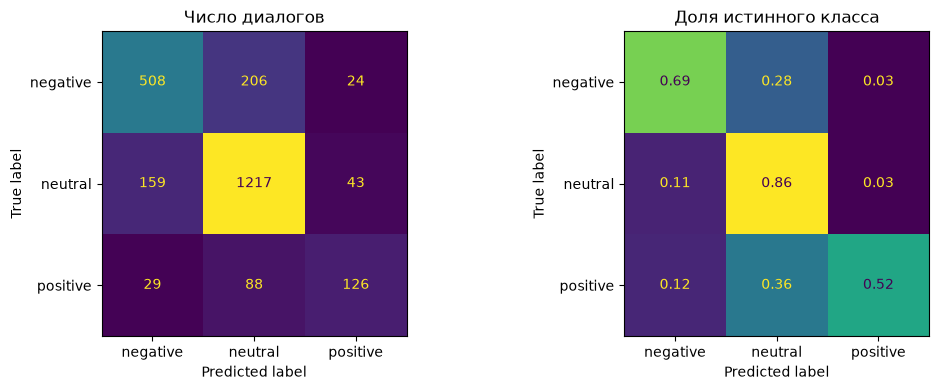

Decision_2x
OOF Macro-F1: 0.7117; mean CV: 0.7128
              precision    recall  f1-score   support

    negative       0.73      0.70      0.72       738
     neutral       0.81      0.86      0.83      1419
    positive       0.69      0.51      0.59       243

    accuracy                           0.78      2400
   macro avg       0.74      0.69      0.71      2400
weighted avg       0.77      0.78      0.77      2400



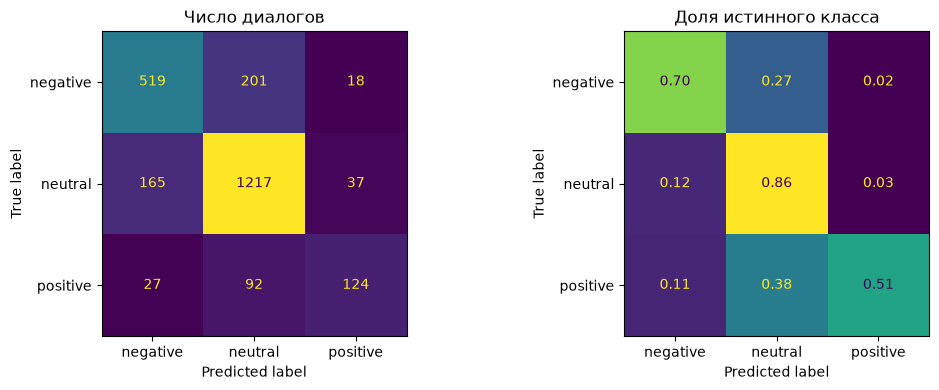

Mean CV Δ Macro-F1: +0.0070; улучшение на 5/5 фолдах


In [9]:
import experiments.course_decision_weight as weight_model
CONTROL_CONFIGS = [(0.1, 'balanced'), (0.3, 'balanced'), (1.0, 'balanced')]
CONTROL_POLICIES = [(1.0, 1.0, 1.0), (2.0, 2.0, 2.0)]
N_N_JOBS = min(2, joblib.cpu_count())
weight_result = weight_model.run(
    train_data,
    configs=CONTROL_CONFIGS,
    policies=CONTROL_POLICIES,
    n_jobs=N_N_JOBS,
    normalize_dialogues=False,
)
weight_model.display_result(weight_result)
paired_control = weight_result['fold_scores'].pivot(index='fold', columns='variant', values='macro_f1')
control_delta = paired_control['Decision_2x'] - paired_control['G_signals']
print(f'Mean CV Δ Macro-F1: {control_delta.mean():+.4f}; улучшение на {(control_delta > 0).sum()}/{len(control_delta)} фолдах')


### копия текста без кода

исходный текст оставляем, очищенный добавляем отдельной веткой tf-idf

Train: 2400 диалогов; групп: 2390
Параллельных SVM: 2 Архив: /home/nika/ML_labs/colab/experiment_O_colab.zip
Отложенный тест не загружается. Результаты: /home/nika/ML_labs/artifacts/course_clean_text
G_signals fold 1/5: 0.7099
G_raw_clean fold 1/5: 0.6816
G_signals fold 2/5: 0.6926
G_raw_clean fold 2/5: 0.6756
G_signals fold 3/5: 0.7786
G_raw_clean fold 3/5: 0.7700
G_signals fold 4/5: 0.7005
G_raw_clean fold 4/5: 0.6924
G_signals fold 5/5: 0.6470
G_raw_clean fold 5/5: 0.6397
Время: 11.7 мин


,OOF_Macro_F1,Mean_CV_Macro_F1,Delta_vs_G
variant,,,
G_signals,0.7057,0.7057,0.0000
G_raw_clean,0.6915,0.6918,-0.0142


variant,G_raw_clean,G_signals,clean_minus_control
fold,,,
1,0.6816,0.7099,-0.0283
2,0.6756,0.6926,-0.0170
3,0.7700,0.7786,-0.0086
4,0.6924,0.7005,-0.0081
5,0.6397,0.6470,-0.0073


G_signals
OOF Macro-F1: 0.7057; mean CV: 0.7057
              precision    recall  f1-score   support

    negative       0.73      0.69      0.71       738
     neutral       0.81      0.86      0.83      1419
    positive       0.65      0.52      0.58       243

    accuracy                           0.77      2400
   macro avg       0.73      0.69      0.71      2400
weighted avg       0.77      0.77      0.77      2400



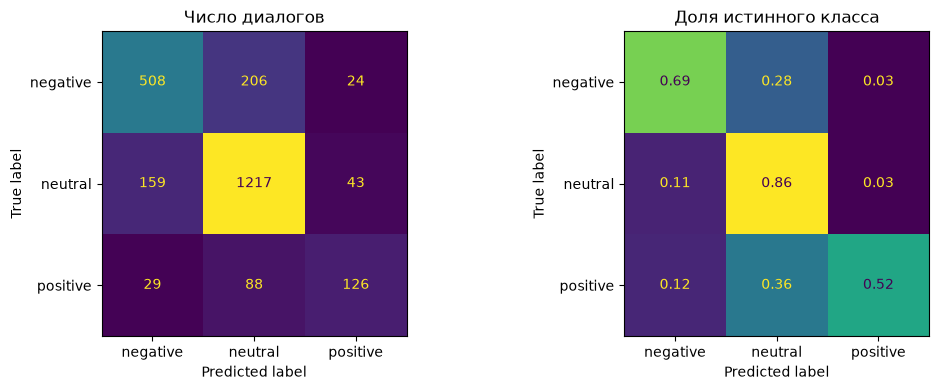

G_raw_clean
OOF Macro-F1: 0.6915; mean CV: 0.6918
              precision    recall  f1-score   support

    negative       0.70      0.69      0.69       738
     neutral       0.80      0.84      0.82      1419
    positive       0.65      0.50      0.56       243

    accuracy                           0.76      2400
   macro avg       0.71      0.68      0.69      2400
weighted avg       0.75      0.76      0.75      2400



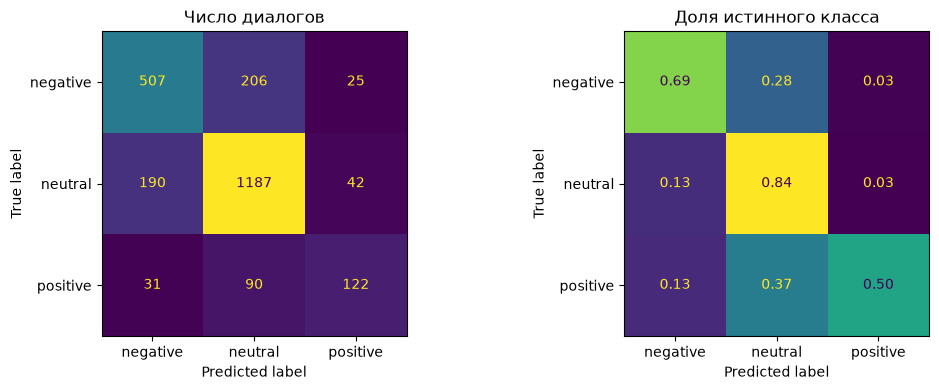

In [10]:
import experiments.course_clean_text as weight_model
O_N_JOBS = min(2, joblib.cpu_count())
weight_result = weight_model.run(train_data, n_jobs=O_N_JOBS)
weight_model.display_result(weight_result)


### больше веса positive

сначала 3/4/6 для решающих positive. потом только для пропущенных, их ищем по внутренним oof

In [12]:
import experiments.course_positive_weight as weight_model
weight_result = weight_model.run(train_data, hard_mining=False)
weight_model.display_result(weight_result)


Train: 2400 диалогов; групп: 2390
Архив: /home/nika/ML_labs/colab/experiment_P_colab.zip Hard mining: False
Отложенный тест не загружается. Результаты: /home/nika/ML_labs/artifacts/course_positive_weight
Decision_2x fold 1/5: 0.7265
Positive_3x fold 1/5: 0.7265
Positive_4x fold 1/5: 0.7265
Positive_6x fold 1/5: 0.7166
Decision_2x fold 2/5: 0.6929
Positive_3x fold 2/5: 0.6929
Positive_4x fold 2/5: 0.6868
Positive_6x fold 2/5: 0.6929
Decision_2x fold 3/5: 0.7862
Positive_3x fold 3/5: 0.7898
Positive_4x fold 3/5: 0.7898
Positive_6x fold 3/5: 0.7814


KeyboardInterrupt: 

In [ ]:
import experiments.course_positive_weight as weight_model
weight_result = weight_model.run(train_data, hard_mining=True)
weight_model.display_result(weight_result)


### complementnb

попробуем его оценки для нейтральности. знак всё ещё от svm

Train: 2400 диалогов; групп: 2390
Архив: /home/nika/ML_labs/colab/experiment_Q_colab.zip Папка совместимых моделей P: /home/nika/ML_labs/artifacts/course_positive_weight
Отложенный тест не загружается. Результаты: /home/nika/ML_labs/artifacts/course_nb_gate
NB gate outer 1/5, inner 1/3
NB gate outer 1/5, inner 2/3
NB gate outer 1/5, inner 3/3
Using compatible saved Decision_2x models: /home/nika/ML_labs/artifacts/course_positive_weight/be97874a676626da/shared_models/fold1
Decision_2x fold 1: 0.7265
Gate_G fold 1: 0.6985
Gate_G_NB fold 1: 0.7259
NB gate outer 2/5, inner 1/3
NB gate outer 2/5, inner 2/3
NB gate outer 2/5, inner 3/3
Using compatible saved Decision_2x models: /home/nika/ML_labs/artifacts/course_positive_weight/be97874a676626da/shared_models/fold2
Decision_2x fold 2: 0.6929
Gate_G fold 2: 0.6708
Gate_G_NB fold 2: 0.6833
NB gate outer 3/5, inner 1/3
NB gate outer 3/5, inner 2/3
NB gate outer 3/5, inner 3/3
Using compatible saved Decision_2x models: /home/nika/ML_labs/artifac

,OOF_Macro_F1,Mean_CV_Macro_F1,Delta_vs_Decision_2x
variant,,,
Decision_2x,0.7117,0.7128,0.0000
Gate_G,0.6938,0.6945,-0.0179
Gate_G_NB,0.7068,0.7067,-0.0049


variant,Decision_2x,Gate_G,Gate_G_NB,NB_minus_G_gate
fold,,,,
1,0.7265,0.6985,0.7259,0.0274
2,0.6929,0.6708,0.6833,0.0125
3,0.7862,0.7697,0.7693,-0.0004
4,0.7049,0.6939,0.6966,0.0027
5,0.6533,0.6398,0.6584,0.0186


Decision_2x
OOF Macro-F1: 0.7117; mean CV: 0.7128
              precision    recall  f1-score   support

    negative       0.73      0.70      0.72       738
     neutral       0.81      0.86      0.83      1419
    positive       0.69      0.51      0.59       243

    accuracy                           0.78      2400
   macro avg       0.74      0.69      0.71      2400
weighted avg       0.77      0.78      0.77      2400



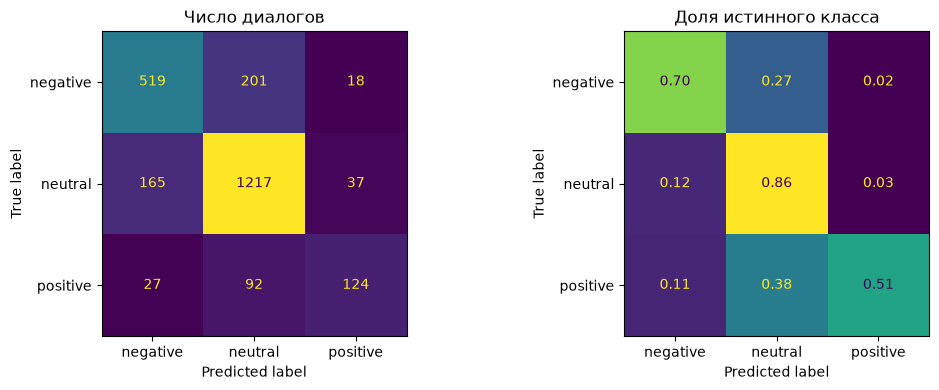

Gate_G
OOF Macro-F1: 0.6938; mean CV: 0.6945
              precision    recall  f1-score   support

    negative       0.71      0.68      0.70       738
     neutral       0.80      0.86      0.83      1419
    positive       0.70      0.47      0.56       243

    accuracy                           0.76      2400
   macro avg       0.74      0.67      0.69      2400
weighted avg       0.76      0.76      0.76      2400



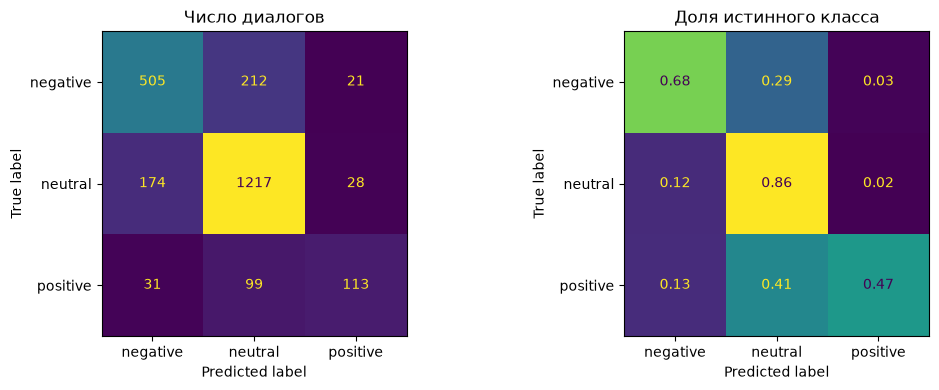

Gate_G_NB
OOF Macro-F1: 0.7068; mean CV: 0.7067
              precision    recall  f1-score   support

    negative       0.74      0.68      0.71       738
     neutral       0.80      0.88      0.84      1419
    positive       0.72      0.47      0.57       243

    accuracy                           0.78      2400
   macro avg       0.75      0.68      0.71      2400
weighted avg       0.77      0.78      0.77      2400



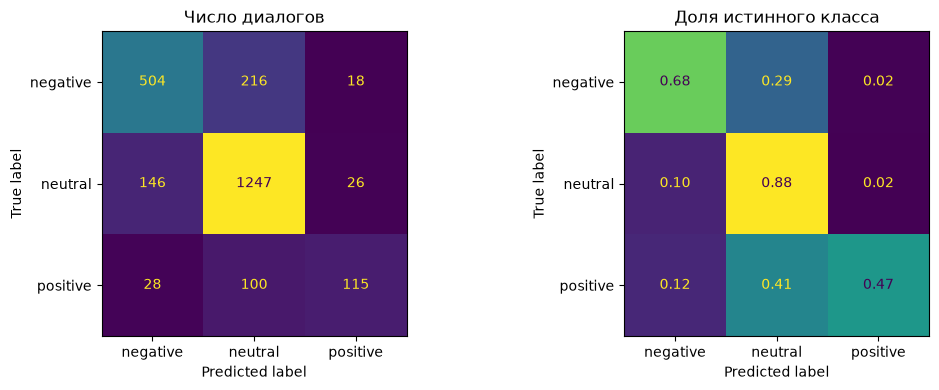

In [14]:
import experiments.course_nb_gate as weight_model
NB_SUB_SPLITS = 2
Q_REUSE_P_DIR = Path('artifacts/course_positive_weight')
nb_result_key = weight_model.fingerprint(train_data, weight_model.CONFIGS, 5, 3, NB_SUB_SPLITS)
nb_result_path = weight_model.RESULT_DIR / nb_result_key[:16] / 'results.joblib'
weight_result = weight_model.run(train_data, sub_splits=NB_SUB_SPLITS, reuse_p_dir=Q_REUSE_P_DIR)
weight_model.display_result(weight_result)


### где ответы расходятся

oof уже есть, посчитаем исправления и новые ошибки

In [ ]:
DISAGREEMENT_RESULTS = nb_result_path
DISAGREEMENT_OUTPUT = Path('artifacts/nb_disagreement')
if not DISAGREEMENT_RESULTS.exists():
    raise FileNotFoundError('Укажите путь к results.joblib завершённого эксперимента Q')
nb_compare = joblib.load(DISAGREEMENT_RESULTS)
nb_names = ['Decision_2x', 'Gate_G_NB']
nb_ids = list(nb_compare['dialog_ids'])
nb_y = np.asarray(nb_compare['y'])
nb_old, nb_new = [np.asarray(nb_compare['predictions'][name]) for name in nb_names]
if len(set(nb_ids)) != len(nb_ids) or not len(nb_ids) == len(nb_y) == len(nb_old) == len(nb_new):
    raise ValueError('Несовместимые размеры/идентификаторы OOF')
if any((not set(values) <= set(['negative', 'neutral', 'positive']) for values in [nb_y, nb_old, nb_new])):
    raise ValueError('Неизвестные классы')
nb_train = df_reaction.iloc[train_idx].reset_index(drop=True)
if nb_train.dialog_id.tolist() != nb_ids or not np.array_equal(nb_train.reaction.to_numpy(), nb_y):
    raise ValueError('OOF не соответствует обучающим диалогам Q')
nb_fold = np.full(len(nb_ids), -1, dtype=int)
for fold, (tr, va) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(nb_train, nb_train.reaction, nb_train.group), 1):
    if set(nb_train.group.iloc[tr]) & set(nb_train.group.iloc[va]):
        raise ValueError('Группа пересекает train/validation')
    nb_fold[va] = fold
    for name, values in zip(nb_names, [nb_old, nb_new]):
        actual = f1_score(
            nb_y[va],
            values[va],
            labels=['negative', 'neutral', 'positive'],
            average='macro',
            zero_division=0,
        )
        saved = nb_compare['fold_scores'].query('variant == @name and fold == @fold')
        if len(saved) != 1 or not np.isclose(actual, float(saved.macro_f1.iloc[0]), atol=1e-10):
            raise ValueError('Фолды не совпали с сохранённой CV')
nb_correct_old = nb_old == nb_y
nb_correct_new = nb_new == nb_y
nb_case = np.select(
    [nb_correct_old & nb_correct_new, ~nb_correct_old & nb_correct_new, nb_correct_old & ~nb_correct_new],
    ['both_correct', 'NB_gate_fixes', 'NB_gate_breaks'],
    default='both_wrong',
)
nb_detail = pd.DataFrame({'dialog_id': nb_ids, 'fold': nb_fold, 'truth': nb_y, 'Decision_2x': nb_old, 'Gate_G_NB': nb_new, 'case': nb_case, 'disagree': nb_old != nb_new})
nb_order = ['both_correct', 'NB_gate_fixes', 'NB_gate_breaks', 'both_wrong']
nb_counts = nb_detail.case.value_counts().reindex(nb_order, fill_value=0).rename('n').to_frame()
nb_counts['share'] = nb_counts.n / len(nb_detail)
display(nb_counts.round(4))
print('Расхождений:', int(nb_detail.disagree.sum()), '; оба неверны, но ответы разные:', int((~nb_correct_old & ~nb_correct_new & nb_detail.disagree).sum()))
nb_class_table = pd.crosstab(nb_detail.truth, nb_detail.case).reindex(columns=nb_order, fill_value=0)
nb_class_table['net_fixed'] = nb_class_table.NB_gate_fixes - nb_class_table.NB_gate_breaks
display(nb_class_table)
nb_paired = nb_compare['fold_scores'].pivot(index='fold', columns='variant', values='macro_f1')
nb_paired['NB_vs_Decision'] = nb_paired.Gate_G_NB - nb_paired.Decision_2x
nb_paired['NB_vs_G_gate'] = nb_paired.Gate_G_NB - nb_paired.Gate_G
display(nb_paired.round(4))
nb_transitions = nb_detail[nb_detail.disagree].groupby(['truth', 'Decision_2x', 'Gate_G_NB']).size().rename('n').reset_index()
display(nb_transitions)
nb_fixed = int((nb_case == 'NB_gate_fixes').sum())
nb_broken = int((nb_case == 'NB_gate_breaks').sum())
print(f'NB-gate исправляет {nb_fixed} ошибок Decision_2x и портит {nb_broken} его верных ответов.')
print(f'Доля исправленных ошибок Decision_2x: {nb_fixed / max(int((~nb_correct_old).sum()), 1):.1%}')
nb_oracle = np.where(nb_correct_old, nb_old, nb_new)
print('Диагностический oracle Macro-F1, недоступный реальной модели:', round(f1_score(nb_y, nb_oracle, labels=['negative', 'neutral', 'positive'], average='macro', zero_division=0), 4))
nb_g = np.asarray(nb_compare['predictions']['Gate_G'])
nb_nb_only = pd.crosstab(
    pd.Series(nb_y, name='truth'),
    pd.Series(np.select([(nb_g != nb_y) & nb_correct_new, (nb_g == nb_y) & ~nb_correct_new], ['NB_fixes_G_gate', 'NB_breaks_G_gate'], default='unchanged_correctness'), name='effect'),
)
display(nb_nb_only)
DISAGREEMENT_OUTPUT.mkdir(parents=True, exist_ok=True)
nb_detail.to_csv(DISAGREEMENT_OUTPUT / 'all_dialogues.csv', index=False)
nb_detail[nb_detail.disagree].to_csv(DISAGREEMENT_OUTPUT / 'disagreements.csv', index=False)
nb_counts.to_csv(DISAGREEMENT_OUTPUT / 'summary.csv')
nb_class_table.to_csv(DISAGREEMENT_OUTPUT / 'by_true_class.csv')
nb_paired.to_csv(DISAGREEMENT_OUTPUT / 'paired_folds.csv')
nb_transitions.to_csv(DISAGREEMENT_OUTPUT / 'prediction_transitions.csv', index=False)
nb_by_id = {r['dialog_id']: r for r in nb_train.to_dict('records')}
nb_examples = []
for case in ['NB_gate_fixes', 'NB_gate_breaks']:
    subset = nb_detail[nb_detail.case == case]
    chosen = subset.sample(n=min(30, len(subset)), random_state=42)
    for row in chosen.to_dict('records'):
        dialog = nb_by_id[row['dialog_id']]
        nb_examples.append({**row, 'user_text': '\n\n'.join((t['text'] for t in dialog['turns'] if t['role'] == 'user')), 'turns': dialog['turns']})
    display(chosen.head(10))
pd.DataFrame(nb_examples).to_json(DISAGREEMENT_OUTPUT / 'examples.jsonl', orient='records', lines=True, force_ascii=False)


### lr поверх оценок

svm + nb -> lr на три класса. не помогло: 0.6559 против 0.7128 у Decision_2x. дальше не подбираем

,OOF_Macro_F1,Mean_CV_Macro_F1,Delta_vs_Decision_2x
variant,,,
Decision_2x,0.7117,0.7128,0.0000
Score_LR,0.6554,0.6559,-0.0568


variant,Decision_2x,Score_LR,delta
fold,,,
1,0.7265,0.6314,-0.0951
2,0.6929,0.6769,-0.0160
3,0.7862,0.6920,-0.0942
4,0.7049,0.6574,-0.0475
5,0.6533,0.6219,-0.0314


Mean CV Δ=-0.0568; minimum requested=0.010
Критерий не выполнен: по вашему правилу направление закрываем.
Decision_2x
OOF Macro-F1: 0.7117; mean CV: 0.7128
              precision    recall  f1-score   support

    negative       0.73      0.70      0.72       738
     neutral       0.81      0.86      0.83      1419
    positive       0.69      0.51      0.59       243

    accuracy                           0.78      2400
   macro avg       0.74      0.69      0.71      2400
weighted avg       0.77      0.78      0.77      2400



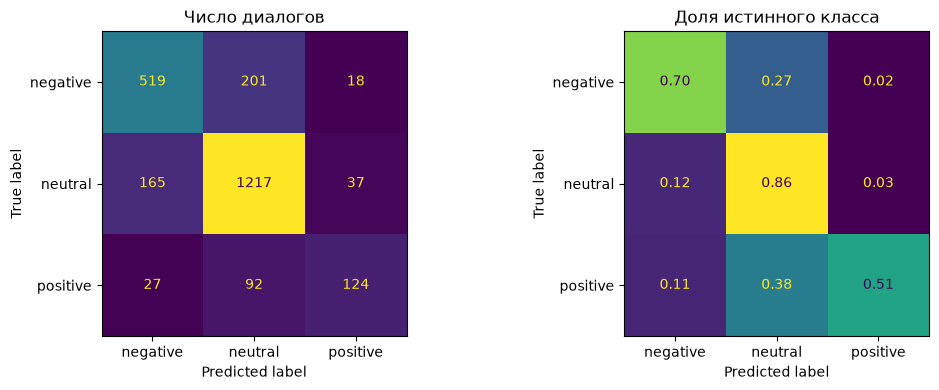

Score_LR
OOF Macro-F1: 0.6554; mean CV: 0.6559
              precision    recall  f1-score   support

    negative       0.70      0.72      0.71       738
     neutral       0.84      0.72      0.77      1419
    positive       0.38      0.67      0.49       243

    accuracy                           0.71      2400
   macro avg       0.64      0.70      0.66      2400
weighted avg       0.75      0.71      0.72      2400



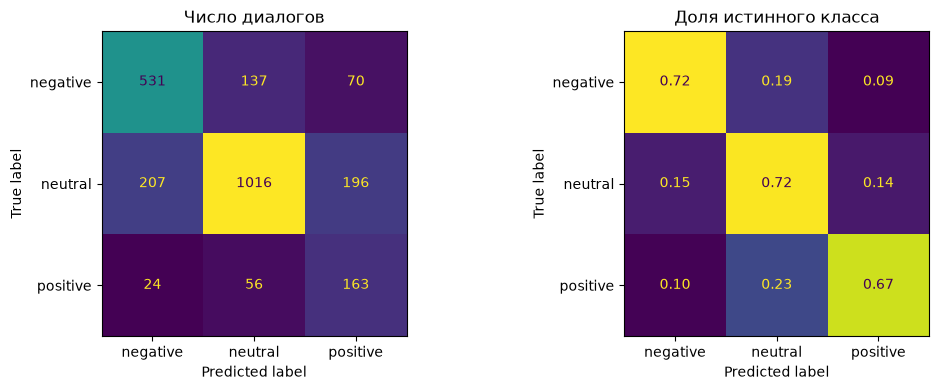

In [15]:
import experiments.course_score_stack as score_stack
stack_result = score_stack.run(
    train_data,
    nb_result_path.parent,
    reuse_p_dir=Path('artifacts/course_positive_weight'),
)
score_stack.display_result(stack_result, min_delta=0.01)
